# REES46 — Ejecución FULL (v7)

Este notebook es el **código completo v7**, configurado con `RUN_MODE = "full"` y `MAX_EVENTS = 10_000_000`.

**Antes de ejecutar:** Colab puede tardar bastante, consumir mucha RAM o desconectarse. Ejecuta con el CSV `2019-Oct.csv` accesible. Si la ejecución se interrumpe, no implica que haya procesado diez millones de eventos. Las escalas efectivamente medidas se registran en `evidencias_eda_v7/inventario_v7.json`.

**Nota metodológica:** las 100 repeticiones se aplican a tamaños pequeños, mientras que los benchmarks originales reducen repeticiones para tamaños ≥1M. El B+Tree indexa productos únicos, no diez millones de productos. No mezclar métricas de ejecuciones quick y full.

# Motor EDA REES46 — v7 | Entrega integral y demostración final

**Código completo de las etapas 0–9**, auditorías v4–v6, B+Tree propio persistente, evaluación de recomendadores, LSH, HNSW, Louvain, benchmarks y dashboard. La sección v7 agrega medición robusta y un guion de demostración. **Ejecutar de arriba hacia abajo en Google Colab**. Resultados solo son evidencia cuando se ejecutan sobre REES46; no se simulan métricas faltantes.

In [ ]:
# Configuración. Cambiar el mes o el tope no crea otro archivo de datos.
DATASET_FILE = "2019-Oct.csv"
MAX_EVENTS = 10_000_000
RUN_MODE = "full"  # primero quick; después full para cobertura ampliada
SEED = 42

EVENTOS_A_LEER = 100_000 if RUN_MODE == "quick" else MAX_EVENTS
TAMANOS_BENCH = (
    [1_000, 10_000, 100_000]
    if RUN_MODE == "quick"
    else [1_000, 10_000, 100_000, 1_000_000, 10_000_000]
)
REPETICIONES_QUICK = 7
REPETICIONES_FULL = 100
VECTOR_DIM = 14  # 1 precio + 1 popularidad + 8 categoría + 4 marca
CUOTA_HNSW = 1
CUOTA_GRAFO = 4
UMBRAL_INTENSIDAD = 8
FRAUDE_MODULO = 125  # cerca del 0,8 % de las compras
MIN_INTERACCIONES = 2
MAX_PRODUCTOS_INDICE = 20_000
MAX_PRODUCTOS_SESION = 40

print("Modo:", RUN_MODE)
print("Archivo:", DATASET_FILE)
print("Eventos a leer:", EVENTOS_A_LEER)
print("Semilla:", SEED)


Modo: full
Archivo: 2019-Oct.csv
Eventos a leer: 10000000
Semilla: 42


In [ ]:
import hashlib
import heapq
import math
import platform
import random
import time
import tracemalloc
from bisect import bisect_left, bisect_right
from collections import Counter, OrderedDict, defaultdict, deque
from itertools import combinations

import numpy as np
import pandas as pd

rng = random.Random(SEED)
np.random.seed(SEED)


def huella(*partes):
    texto = "|".join(map(str, partes)).encode()
    return int.from_bytes(hashlib.sha256(texto).digest()[:8], "little")


def repeticiones_para(n):
    if RUN_MODE == "quick":
        return REPETICIONES_QUICK
    if n >= 1_000_000:
        # 100 repeticiones de estructuras sobre 1M o 10M no caben en una corrida de clase.
        return 3
    return REPETICIONES_FULL


print("Plataforma:", platform.platform())
print("Semilla:", SEED)


Plataforma: Linux-6.6.122+-x86_64-with-glibc2.39
Semilla: 42


## Carga

Se localiza solo `DATASET_FILE` dentro del dataset de REES46. La lectura es por bloques y se detiene al llegar al tope del modo.


In [ ]:
def ubicar_archivo(nombre):
    import os
    candidatos = []
    try:
        import kagglehub
        raiz = kagglehub.dataset_download(
            "mkechinov/ecommerce-behavior-data-from-multi-category-store"
        )
        candidatos.append(os.path.join(raiz, nombre))
    except Exception as exc:
        print("No se usó kagglehub:", exc)
    candidatos.append(os.path.join(os.getcwd(), nombre))
    for ruta in candidatos:
        if os.path.exists(ruta):
            print("Fuente:", ruta)
            return ruta
    raise FileNotFoundError(
        f"No está {nombre}. Cambia DATASET_FILE al mes que quieras usar, "
        "por ejemplo 2019-Nov.csv. No se descargan los siete meses."
    )


def leer_eventos(ruta, max_eventos):
    columnas = [
        "event_time", "event_type", "product_id", "category_id",
        "category_code", "brand", "price", "user_id", "user_session",
    ]
    bloques = []
    restante = max_eventos
    lector = pd.read_csv(ruta, usecols=columnas, chunksize=min(250_000, max_eventos))
    for bloque in lector:
        if len(bloque) > restante:
            bloque = bloque.iloc[:restante]
        bloques.append(bloque)
        restante -= len(bloque)
        if restante <= 0:
            break
    if not bloques:
        raise RuntimeError("El archivo no tiene filas.")
    return pd.concat(bloques, ignore_index=True)


## Núcleo

La limpieza ordena con merge sort. Hasta 100.000 filas el ordenamiento es interno. Por encima de eso, ordena bloques y los mezcla: es el mismo algoritmo, apto para el modo `full`.

Después el lote histórico (60 %) construye el almacén y los modelos. El 40 % restante es el stream vivo: cola, heap y ramas.


In [ ]:
def merge_sort(items, clave):
    if len(items) <= 1:
        return list(items)
    tamaño = 1
    ordenados = list(items)
    while tamaño < len(ordenados):
        siguiente = []
        for inicio in range(0, len(ordenados), tamaño * 2):
            izquierda = ordenados[inicio:inicio + tamaño]
            derecha = ordenados[inicio + tamaño:inicio + tamaño * 2]
            i = j = 0
            while i < len(izquierda) and j < len(derecha):
                if clave(izquierda[i]) <= clave(derecha[j]):
                    siguiente.append(izquierda[i])
                    i += 1
                else:
                    siguiente.append(derecha[j])
                    j += 1
            siguiente.extend(izquierda[i:])
            siguiente.extend(derecha[j:])
        ordenados = siguiente
        tamaño *= 2
    return ordenados


def mezcla_k(bloques, clave):
    heap = []
    for b, bloque in enumerate(bloques):
        if bloque:
            heapq.heappush(heap, (clave(bloque[0]), b, 0, bloque[0]))
    salida = []
    while heap:
        _, b, pos, valor = heapq.heappop(heap)
        salida.append(valor)
        pos += 1
        if pos < len(bloques[b]):
            valor = bloques[b][pos]
            heapq.heappush(heap, (clave(valor), b, pos, valor))
    return salida


def ordenar_indices(indices, tiempos, tamano_bloque=100_000):
    def clave(indice):
        return (tiempos[indice], indice)

    if len(indices) <= tamano_bloque:
        return merge_sort(indices, clave)
    bloques = []
    for inicio in range(0, len(indices), tamano_bloque):
        parte = indices[inicio:inicio + tamano_bloque]
        bloques.append(merge_sort(parte, clave))
    return mezcla_k(bloques, clave)


def busqueda_binaria(ordenado, objetivo):
    bajo, alto = 0, len(ordenado) - 1
    while bajo <= alto:
        medio = (bajo + alto) // 2
        if ordenado[medio] == objetivo:
            return medio
        if ordenado[medio] < objetivo:
            bajo = medio + 1
        else:
            alto = medio - 1
    return -1


class CacheLRU:
    def __init__(self, capacidad=256):
        self.capacidad = capacidad
        self.cache = OrderedDict()
        self.aciertos = 0
        self.fallos = 0

    def obtener(self, clave):
        if clave in self.cache:
            self.cache.move_to_end(clave)
            self.aciertos += 1
            return self.cache[clave]
        self.fallos += 1
        return None

    def guardar(self, clave, valor):
        if clave in self.cache:
            self.cache.move_to_end(clave)
        self.cache[clave] = valor
        if len(self.cache) > self.capacidad:
            self.cache.popitem(last=False)


class NodoBPlus:
    def __init__(self, hoja=False):
        self.hoja = hoja
        self.claves = []
        self.hijos = []
        self.siguiente = None


class ArbolBPlus:
    # Árbol en memoria con la interfaz de un índice de disco: puntual y por rango.
    def __init__(self, orden=32):
        self.orden = orden
        self.raiz = NodoBPlus(hoja=True)

    def insertar(self, clave, valor):
        clave = float(clave)
        promovido = self._insertar(self.raiz, clave, valor)
        if promovido is not None:
            separador, derecho = promovido
            raiz = NodoBPlus(hoja=False)
            raiz.claves = [separador]
            raiz.hijos = [self.raiz, derecho]
            self.raiz = raiz

    def _insertar(self, nodo, clave, valor):
        if nodo.hoja:
            i = bisect_left(nodo.claves, clave)
            if i < len(nodo.claves) and nodo.claves[i] == clave:
                nodo.hijos[i].append(valor)
            else:
                nodo.claves.insert(i, clave)
                nodo.hijos.insert(i, [valor])
            if len(nodo.claves) <= self.orden:
                return None
            return self._dividir_hoja(nodo)
        i = bisect_right(nodo.claves, clave)
        promovido = self._insertar(nodo.hijos[i], clave, valor)
        if promovido is None:
            return None
        separador, derecho = promovido
        nodo.claves.insert(i, separador)
        nodo.hijos.insert(i + 1, derecho)
        if len(nodo.claves) <= self.orden:
            return None
        return self._dividir_interno(nodo)

    def _dividir_hoja(self, nodo):
        medio = len(nodo.claves) // 2
        nuevo = NodoBPlus(hoja=True)
        nuevo.claves = nodo.claves[medio:]
        nuevo.hijos = nodo.hijos[medio:]
        nodo.claves = nodo.claves[:medio]
        nodo.hijos = nodo.hijos[:medio]
        nuevo.siguiente = nodo.siguiente
        nodo.siguiente = nuevo
        return nuevo.claves[0], nuevo

    def _dividir_interno(self, nodo):
        medio = len(nodo.claves) // 2
        separador = nodo.claves[medio]
        nuevo = NodoBPlus(hoja=False)
        nuevo.claves = nodo.claves[medio + 1:]
        nuevo.hijos = nodo.hijos[medio + 1:]
        nodo.claves = nodo.claves[:medio]
        nodo.hijos = nodo.hijos[:medio + 1]
        return separador, nuevo

    def buscar_rango(self, minimo, maximo):
        nodo = self.raiz
        while not nodo.hoja:
            nodo = nodo.hijos[bisect_right(nodo.claves, minimo)]
        salida = []
        while nodo is not None:
            for clave, valores in zip(nodo.claves, nodo.hijos):
                if minimo <= clave <= maximo:
                    salida.extend(valores)
                elif clave > maximo:
                    return salida
            nodo = nodo.siguiente
        return salida


class Almacen:
    def __init__(self):
        self.catalogo = {}
        self.lru = CacheLRU(256)
        self.precios = ArbolBPlus()
        self.interacciones = {}
        self.pares = 0

    def actualizar(self, evento):
        producto = int(evento["product_id"])
        usuario = int(evento["user_id"])
        if producto not in self.catalogo:
            self.catalogo[producto] = {
                "categoria": evento["category_code"],
                "marca": evento["brand"],
                "precio": float(evento["price"]),
                "disponible": bool(evento["disponible"]),
                "popularidad": 0,
            }
            self.precios.insertar(float(evento["price"]), producto)
        self.catalogo[producto]["popularidad"] += 1
        por_usuario = self.interacciones.setdefault(usuario, {})
        if producto not in por_usuario:
            self.pares += 1
        por_usuario[producto] = por_usuario.get(producto, 0) + 1
        return self.consultar(producto)

    def consultar(self, producto):
        en_cache = self.lru.obtener(producto)
        if en_cache is not None:
            return en_cache, "CACHE"
        item = self.catalogo.get(producto)
        if item is None:
            return None, "NO ENCONTRADO"
        self.lru.guardar(producto, item)
        return item, "HASH"

    def memoria_dispersa(self):
        usuarios = len(self.interacciones)
        productos = len(self.catalogo)
        densa = usuarios * productos * 8
        dispersa = self.pares * 32
        return {
            "usuarios": usuarios,
            "productos": productos,
            "pares": self.pares,
            "densa_mb": densa / (1024 ** 2),
            "dispersa_mb": dispersa / (1024 ** 2),
        }


In [ ]:
class BloomFilter:
    def __init__(self, capacidad, error=0.01):
        capacidad = max(1, int(capacidad))
        self.m = max(8, math.ceil(-(capacidad * math.log(error)) / (math.log(2) ** 2)))
        self.k = max(1, round((self.m / capacidad) * math.log(2)))
        self.bits = bytearray(math.ceil(self.m / 8))

    def _posiciones(self, elemento):
        texto = str(elemento).encode()
        for i in range(self.k):
            digest = hashlib.sha256(i.to_bytes(2, "little") + texto).digest()
            yield int.from_bytes(digest[:4], "little") % self.m

    def agregar(self, elemento):
        for pos in self._posiciones(elemento):
            self.bits[pos // 8] |= 1 << (pos % 8)

    def contiene(self, elemento):
        return all(self.bits[pos // 8] & (1 << (pos % 8)) for pos in self._posiciones(elemento))


class CountMinSketch:
    def __init__(self, ancho=4096, profundidad=5):
        self.ancho = ancho
        self.profundidad = profundidad
        self.tabla = np.zeros((profundidad, ancho), dtype=np.int64)

    def _pos(self, elemento, i):
        digest = hashlib.sha256(f"{i}|{elemento}".encode()).digest()
        return int.from_bytes(digest[:4], "little") % self.ancho

    def agregar(self, elemento, veces=1):
        for i in range(self.profundidad):
            self.tabla[i, self._pos(elemento, i)] += veces

    def estimar(self, elemento):
        return int(min(self.tabla[i, self._pos(elemento, i)] for i in range(self.profundidad)))


class Trie:
    def __init__(self):
        self.raiz = {}

    def insertar(self, texto, valor):
        nodo = self.raiz
        for caracter in str(texto).lower():
            nodo = nodo.setdefault(caracter, {})
        nodo.setdefault("_vals", []).append(valor)

    def completar(self, prefijo, limite=5):
        nodo = self.raiz
        for caracter in str(prefijo).lower():
            if caracter not in nodo:
                return []
            nodo = nodo[caracter]
        cola = deque([nodo])
        hallados = []
        while cola and len(hallados) < limite:
            actual = cola.popleft()
            hallados.extend(actual.get("_vals", []))
            for caracter in sorted(clave for clave in actual if clave != "_vals"):
                cola.append(actual[caracter])
        return hallados[:limite]


def agregar_arista(grafo, a, b, peso=1):
    if a == b:
        return
    grafo.setdefault(a, {})
    grafo.setdefault(b, {})
    grafo[a][b] = grafo[a].get(b, 0) + peso
    grafo[b][a] = grafo[b].get(a, 0) + peso


def construir_grafo_sesion(df):
    grafo = {}
    sesiones = df.groupby("user_session", sort=False)["product_id"]
    for _, productos in sesiones:
        unicos = list(dict.fromkeys(int(p) for p in productos))[:MAX_PRODUCTOS_SESION]
        for a, b in combinations(unicos, 2):
            agregar_arista(grafo, a, b)
    return grafo


def candidatos_grafo(vistos, grafo, k=20):
    puntaje = {}
    vistos = set(vistos)
    for producto in vistos:
        for vecino, peso in grafo.get(producto, {}).items():
            if vecino in vistos:
                continue
            puntaje[vecino] = puntaje.get(vecino, 0) + peso
    orden = sorted(puntaje.items(), key=lambda item: (-item[1], item[0]))
    return [producto for producto, _ in orden[:k]]


def vector_producto(precio, popularidad, categoria, marca, escala):
    precio_n = math.log1p(max(precio, 0.0)) / escala["precio"]
    pop_n = math.log1p(max(popularidad, 0)) / escala["popularidad"]
    vector = [precio_n, pop_n] + [0.0] * 12
    vector[2 + (huella("cat", categoria) % 8)] = 1.0
    vector[10 + (huella("marca", marca) % 4)] = 1.0
    return vector


class IndiceVectorial:
    def __init__(self, vectores, ids):
        self.vectores = np.asarray(vectores, dtype=np.float32)
        self.ids = [int(i) for i in ids]
        self.backend = "knn_exacto"
        self.index = None
        if len(self.ids) == 0:
            return
        try:
            import hnswlib
            indice = hnswlib.Index(space="l2", dim=self.vectores.shape[1])
            indice.init_index(max_elements=len(self.ids), ef_construction=80, M=16)
            indice.add_items(self.vectores, np.arange(len(self.ids)))
            indice.set_ef(40)
            self.index = indice
            self.backend = "hnswlib"
        except Exception:
            self.backend = "knn_exacto"

    def buscar(self, consulta, k):
        if len(self.ids) == 0:
            return [], []
        k = min(k, len(self.ids))
        consulta = np.asarray(consulta, dtype=np.float32).reshape(1, -1)
        if self.index is not None:
            etiquetas, distancias = self.index.knn_query(consulta, k=k)
            return [self.ids[i] for i in etiquetas[0]], distancias[0]
        distancias = np.linalg.norm(self.vectores - consulta[0], axis=1)
        orden = np.argsort(distancias)[:k]
        return [self.ids[i] for i in orden], distancias[orden]


def knn_exacto(vectores, consulta, k):
    distancias = np.linalg.norm(vectores - np.asarray(consulta, dtype=np.float32), axis=1)
    orden = np.argsort(distancias)[:k]
    return orden, distancias[orden]


def construir_indice_productos(df, almacen):
    conteo = Counter()
    for usuario, productos in almacen.interacciones.items():
        for producto in productos:
            conteo[producto] += 1
    elegibles = [p for p, c in conteo.items() if c >= MIN_INTERACCIONES and p in almacen.catalogo]
    elegibles.sort(key=lambda p: conteo[p], reverse=True)
    elegibles = elegibles[:MAX_PRODUCTOS_INDICE]
    if not elegibles:
        elegibles = list(almacen.catalogo)[:MAX_PRODUCTOS_INDICE]
    precio_max = max(math.log1p(max(almacen.catalogo[p]["precio"], 0.0)) for p in elegibles)
    pop_max = max(math.log1p(almacen.catalogo[p]["popularidad"]) for p in elegibles)
    escala = {
        "precio": precio_max if precio_max else 1.0,
        "popularidad": pop_max if pop_max else 1.0,
    }
    vectores = []
    for producto in elegibles:
        item = almacen.catalogo[producto]
        vectores.append(vector_producto(item["precio"], item["popularidad"], item["categoria"], item["marca"], escala))
    return {
        "ids": elegibles,
        "vectores": np.asarray(vectores, dtype=np.float32) if vectores else np.zeros((0, VECTOR_DIM), dtype=np.float32),
        "escala": escala,
        "indice": IndiceVectorial(vectores, elegibles) if vectores else IndiceVectorial(np.zeros((0, VECTOR_DIM)), []),
        "populares": [p for p, _ in Counter(conteo).most_common(20)],
    }


def candidatos_vector(vistos, modelo, k=20):
    posiciones = []
    id_a_pos = {producto: i for i, producto in enumerate(modelo["ids"])}
    for producto in vistos:
        if producto in id_a_pos:
            posiciones.append(id_a_pos[producto])
    if not posiciones:
        return list(modelo["populares"])
    consulta = modelo["vectores"][posiciones].mean(axis=0)
    ids, _ = modelo["indice"].buscar(consulta, k + len(posiciones))
    vistos = set(vistos)
    return [producto for producto in ids if producto not in vistos][:k]


def hibrido(vistos, grafo, modelo, k=5):
    de_vector = candidatos_vector(vistos, modelo, k=20)
    de_grafo = candidatos_grafo(vistos, grafo, k=20)
    salida = []
    vistos = set(vistos)

    def tomar(lista, cupo):
        tomados = 0
        for producto in lista:
            if producto in vistos or producto in salida:
                continue
            salida.append(producto)
            tomados += 1
            if tomados >= cupo or len(salida) >= k:
                break

    tomar(de_vector, CUOTA_HNSW)
    tomar(de_grafo, CUOTA_GRAFO)
    if len(salida) < k:
        tomar(de_vector + de_grafo + modelo["populares"], k)
    return salida[:k]


In [ ]:
def decidir_fraude(evento, bloom, cms, exactos):
    motivos = []
    if bloom.contiene(evento["device_id"]):
        motivos.append("dispositivo")
    if bloom.contiene(evento["payment_id"]):
        motivos.append("pago")
    clave = f"{int(evento['user_id'])}|{evento['hora']}"
    intensidad = cms.estimar(clave)
    if intensidad >= UMBRAL_INTENSIDAD:
        motivos.append(f"intensidad:{intensidad}")
    confirmado = bool(evento["fraude_confirmado"]) or evento["device_id"] in exactos or evento["payment_id"] in exactos
    if confirmado:
        return "bloquear", motivos or ["confirmado"]
    if motivos:
        return "revisar", motivos
    return "permitir", []


def construir_fraude(df, corte):
    historico = df.iloc[:corte]
    confirmados = set()
    vigilados = set()
    cms = CountMinSketch()
    # La ventana es el histórico ya cerrado. No cuenta compras futuras de la misma hora.
    for fila in historico.itertuples(index=False):
        if fila.event_type != "purchase":
            continue
        cms.agregar(f"{int(fila.user_id)}|{fila.hora}")
        if fila.fraude_confirmado:
            confirmados.add(fila.device_id)
            confirmados.add(fila.payment_id)
        elif huella("vigia", fila.device_id) % 50 == 0:
            vigilados.add(fila.device_id)
    miembros = confirmados | vigilados
    bloom = BloomFilter(max(len(miembros), 1024), error=0.01)
    for miembro in miembros:
        bloom.agregar(miembro)
    return {"bloom": bloom, "cms": cms, "exactos": confirmados, "vigilados": len(miembros)}


def construir_cocompra(df, indices):
    try:
        import networkx as nx
    except ImportError:
        nx = None
    compras = df.loc[list(indices)]
    if nx is None:
        return {"nx": None, "grafo": None, "por_sesion": {}, "nodos": 0, "aristas": 0}
    grafo = nx.Graph()
    por_sesion = defaultdict(list)
    for indice, fila in compras.iterrows():
        producto = int(fila["product_id"])
        grafo.add_node(producto)
        por_sesion[fila["user_session"]].append((indice, producto, fila["event_time"]))
    for pares in por_sesion.values():
        pares.sort(key=lambda item: item[2])
        vistos = []
        for _, producto, _ in pares:
            for otro in vistos:
                if otro == producto:
                    continue
                if grafo.has_edge(otro, producto):
                    grafo[otro][producto]["weight"] += 1
                else:
                    grafo.add_edge(otro, producto, weight=1)
            vistos.append(producto)
    return {
        "nx": nx,
        "grafo": grafo,
        "por_sesion": por_sesion,
        "nodos": grafo.number_of_nodes(),
        "aristas": grafo.number_of_edges(),
    }


def unir_compra(estado, indice, producto, sesion, momento):
    grafo = estado["grafo"]
    if grafo is None:
        return 0
    pares = estado["por_sesion"].setdefault(sesion, [])
    previos = [otro for j, otro, cuando in pares if j != indice and cuando < momento]
    grafo.add_node(producto)
    nuevas = 0
    for otro in dict.fromkeys(previos):
        if otro == producto:
            continue
        if grafo.has_edge(otro, producto):
            grafo[otro][producto]["weight"] += 1
        else:
            grafo.add_edge(otro, producto, weight=1)
            nuevas += 1
    pares.append((indice, producto, momento))
    return nuevas


def pagerank_propio(grafo, damping=0.85, iters=30):
    nodos = list(grafo.nodes)
    n = len(nodos)
    if n == 0:
        return {}
    indice = {nodo: i for i, nodo in enumerate(nodos)}
    vecinos = []
    salida = []
    for nodo in nodos:
        pares = []
        total = 0.0
        for _, vecino, datos in grafo.edges(nodo, data=True):
            peso = float(datos.get("weight", 1))
            pares.append((indice[vecino], peso))
            total += peso
        vecinos.append(pares)
        salida.append(total)
    rank = [1.0 / n] * n
    for _ in range(iters):
        nuevo = [(1 - damping) / n] * n
        colgado = 0.0
        for i, total in enumerate(salida):
            if total == 0:
                colgado += rank[i]
        if colgado:
            reparto = damping * colgado / n
            nuevo = [valor + reparto for valor in nuevo]
        for i, pares in enumerate(vecinos):
            if salida[i] == 0:
                continue
            for destino, peso in pares:
                nuevo[destino] += damping * rank[i] * (peso / salida[i])
        rank = nuevo
    return {nodo: rank[indice[nodo]] for nodo in nodos}


def resumen_grafo(estado):
    grafo = estado["grafo"]
    nx = estado["nx"]
    if grafo is None or grafo.number_of_nodes() == 0:
        return {"nodos": 0, "aristas": 0, "pagerank": [], "grado": [], "comunidades": 0, "modularidad": None}
    grado = sorted(grafo.degree(weight="weight"), key=lambda item: item[1], reverse=True)[:10]
    if grafo.number_of_edges() == 0:
        return {
            "nodos": grafo.number_of_nodes(),
            "aristas": 0,
            "pagerank": grado,
            "grado": grado,
            "comunidades": grafo.number_of_nodes(),
            "modularidad": None,
        }
    puntajes = sorted(pagerank_propio(grafo).items(), key=lambda item: item[1], reverse=True)[:10]
    comunidades = []
    modularidad = None
    if nx is not None:
        try:
            comunidades = list(nx.community.louvain_communities(grafo, weight="weight", seed=SEED))
            modularidad = float(nx.community.modularity(grafo, comunidades, weight="weight"))
        except Exception:
            comunidades = list(nx.connected_components(grafo))
    return {
        "nodos": grafo.number_of_nodes(),
        "aristas": grafo.number_of_edges(),
        "pagerank": puntajes,
        "grado": grado,
        "comunidades": len(comunidades),
        "modularidad": modularidad,
        "particion": comunidades,
    }


In [ ]:
def preparar_eventos(df, semilla):
    df = df.copy()
    df = df.dropna(subset=["event_time", "event_type", "product_id", "price", "user_id", "user_session"])
    df["category_code"] = df["category_code"].fillna("unknown").astype(str).replace("", "unknown")
    df["brand"] = df["brand"].fillna("unknown").astype(str).replace("", "unknown")
    df["event_time"] = pd.to_datetime(df["event_time"], utc=True, format="mixed")
    df["product_id"] = df["product_id"].astype("int64")
    df["user_id"] = df["user_id"].astype("int64")
    df["price"] = df["price"].astype(float)
    antes = len(df)
    df = df.drop_duplicates(["event_time", "event_type", "product_id", "user_id", "user_session"])
    duplicados = antes - len(df)
    df = df.reset_index(drop=True)
    tiempos = df["event_time"].astype("int64").to_numpy()
    orden = ordenar_indices(list(range(len(df))), tiempos)
    df = df.iloc[orden].reset_index(drop=True)
    dispositivos = np.empty(len(df), dtype=object)
    pagos = np.empty(len(df), dtype=object)
    entregas = np.empty(len(df), dtype=object)
    fraude = np.zeros(len(df), dtype=bool)
    disponible = np.ones(len(df), dtype=bool)
    prioridad = np.empty(len(df), dtype=np.int16)
    etiqueta = np.empty(len(df), dtype=object)
    nombres_dispositivo = ["mobile", "desktop", "tablet"]
    nombres_pago = ["tarjeta", "billetera", "efectivo"]
    for i, (usuario, producto, tipo) in enumerate(zip(df["user_id"], df["product_id"], df["event_type"])):
        h = huella(semilla, int(usuario), int(producto))
        dispositivos[i] = f"dev-{int(usuario)}-{h % 2}"
        pagos[i] = f"pay-{int(usuario)}-{h % 3}"
        bucket = h % 5
        entregas[i] = "Express" if bucket == 0 else "Programada" if bucket == 4 else "Estandar"
        disponible[i] = (h % 20) != 0
        es_fraude = tipo == "purchase" and (h % FRAUDE_MODULO == 0)
        fraude[i] = es_fraude
        if tipo == "purchase" and es_fraude:
            prioridad[i], etiqueta[i] = 1, "Fraude"
        elif tipo == "purchase" and entregas[i] == "Express":
            prioridad[i], etiqueta[i] = 2, "Express"
        elif tipo == "purchase" and entregas[i] == "Estandar":
            prioridad[i], etiqueta[i] = 3, "Estandar"
        elif tipo == "purchase":
            prioridad[i], etiqueta[i] = 4, "Programada"
        elif tipo == "cart":
            prioridad[i], etiqueta[i] = 5, "Carrito"
        else:
            prioridad[i], etiqueta[i] = 6, "Vista"
    df["device_id"] = dispositivos
    df["payment_id"] = pagos
    df["entrega"] = entregas
    df["fraude_confirmado"] = fraude
    df["disponible"] = disponible
    df["prioridad"] = prioridad
    df["etiqueta_prioridad"] = etiqueta
    df["hora"] = df["event_time"].dt.floor("h").astype(str)
    df["evento_id"] = [f"E{i:08d}" for i in range(len(df))]
    return df, duplicados


def cortes_temporales(n):
    train = max(1, int(n * 0.60))
    val = max(train + 1, int(n * 0.70))
    if val >= n and n > train:
        val = n - 1
    return train, val


def actualizar_almacen(almacen, df, indices):
    for indice in indices:
        almacen.actualizar(df.iloc[indice])


def ejecutar_pipeline(df_crudo):
    df, duplicados = preparar_eventos(df_crudo, SEED)
    n = len(df)
    corte_train, corte_val = cortes_temporales(n)
    almacen = Almacen()
    actualizar_almacen(almacen, df, range(corte_train))
    grafo_sesion = construir_grafo_sesion(df.iloc[:corte_train])
    modelo = construir_indice_productos(df.iloc[:corte_train], almacen)
    fraude = construir_fraude(df, corte_train)
    compras_train = df.index[:corte_train][df.iloc[:corte_train]["event_type"].to_numpy() == "purchase"]
    cocompra = construir_cocompra(df, compras_train)
    trie = Trie()
    for producto, item in almacen.catalogo.items():
        trie.insertar(f"{item['categoria']} {item['marca']}", producto)
        trie.insertar(f"{item['marca']} {item['categoria']}", producto)

    productos_np = df["product_id"].to_numpy()
    prefijos = {}
    indices_sesion = defaultdict(list)
    for indice, sesion in enumerate(df["user_session"].tolist()):
        indices_sesion[sesion].append(indice)
    for indices in indices_sesion.values():
        vistos = []
        for indice in indices:
            prefijos[indice] = list(vistos)
            producto = int(productos_np[indice])
            if producto not in vistos:
                vistos.append(producto)

    cola = deque(range(corte_train, n))
    heap = []
    for orden, indice in enumerate(cola):
        heapq.heappush(heap, (int(df.at[indice, "prioridad"]), orden, indice))
    recibidos = len(cola)
    cola.clear()

    trazas = []
    por_indice = {}
    permitidas = []
    primeros = []
    detallado = n <= 100_000
    while heap:
        prioridad, _, indice = heapq.heappop(heap)
        fila = df.iloc[indice]
        item, origen = almacen.actualizar(fila)
        tipo = fila["event_type"]
        if len(primeros) < 10:
            primeros.append((fila["evento_id"], int(prioridad), fila["etiqueta_prioridad"], int(fila["product_id"])))
        if tipo in ("view", "cart"):
            vistos = prefijos[indice] + [int(fila["product_id"])]
            recomendaciones = hibrido(vistos, grafo_sesion, modelo) if detallado else []
            traza = {
                "evento_id": fila["evento_id"],
                "indice": indice,
                "tipo": tipo,
                "prioridad": int(prioridad),
                "etiqueta": fila["etiqueta_prioridad"],
                "rama": "recomendacion",
                "decision": "consultar",
                "motivos": "",
                "recomendaciones": recomendaciones,
                "actualizo_cocompra": False,
                "aristas_nuevas": 0,
                "origen_lookup": origen,
                "producto": int(fila["product_id"]),
                "texto": f"{fila['category_code']} {fila['brand']}",
            }
        else:
            decision, motivos = decidir_fraude(fila, fraude["bloom"], fraude["cms"], fraude["exactos"])
            traza = {
                "evento_id": fila["evento_id"],
                "indice": indice,
                "tipo": tipo,
                "prioridad": int(prioridad),
                "etiqueta": fila["etiqueta_prioridad"],
                "rama": "fraude",
                "decision": decision,
                "motivos": ",".join(motivos),
                "recomendaciones": [],
                "actualizo_cocompra": False,
                "aristas_nuevas": 0,
                "origen_lookup": origen,
                "producto": int(fila["product_id"]),
                "texto": f"{fila['category_code']} {fila['brand']}",
            }
            if decision != "bloquear":
                permitidas.append(indice)
                traza["rama_final"] = "cocompra"
            else:
                traza["rama_final"] = "fraude"
        trazas.append(traza)
        por_indice[indice] = traza

    tiempos = df["event_time"]
    for indice in sorted(permitidas, key=lambda i: tiempos.iloc[i]):
        fila = df.iloc[indice]
        nuevas = unir_compra(
            cocompra,
            indice,
            int(fila["product_id"]),
            fila["user_session"],
            fila["event_time"],
        )
        por_indice[indice]["actualizo_cocompra"] = True
        por_indice[indice]["aristas_nuevas"] = nuevas

    for traza in elegir_ejemplos(trazas):
        if traza["tipo"] in ("view", "cart") and not traza["recomendaciones"]:
            vistos = prefijos[traza["indice"]] + [traza["producto"]]
            traza["recomendaciones"] = hibrido(vistos, grafo_sesion, modelo)

    ids = sorted(almacen.catalogo)
    buscado = ids[len(ids) // 2]
    posicion = busqueda_binaria(ids, buscado)
    precios = [almacen.catalogo[p]["precio"] for p in ids[:5000]]
    if precios:
        bajo, alto = np.percentile(precios, [40, 60])
        en_rango = almacen.precios.buscar_rango(float(bajo), float(alto))
    else:
        bajo = alto = 0
        en_rango = []
    knn_ok = validar_kd(almacen)
    resumen = resumen_grafo(cocompra)
    panel = {
        "eventos_stream": len(trazas),
        "consultas": sum(t["rama"] == "recomendacion" for t in trazas),
        "ventas": sum(t["tipo"] == "purchase" and t["decision"] != "bloquear" for t in trazas),
        "alertas": sum(t["decision"] in ("revisar", "bloquear") for t in trazas),
        "bloqueos": sum(t["decision"] == "bloquear" for t in trazas),
        "revisiones": sum(t["decision"] == "revisar" for t in trazas),
    }
    return {
        "df": df,
        "duplicados": duplicados,
        "corte_train": corte_train,
        "corte_val": corte_val,
        "almacen": almacen,
        "grafo_sesion": grafo_sesion,
        "modelo": modelo,
        "fraude": fraude,
        "cocompra": cocompra,
        "resumen_grafo": resumen,
        "trie": trie,
        "trazas": trazas,
        "primeros_heap": primeros,
        "recibidos_fifo": recibidos,
        "panel": panel,
        "busqueda": {"producto": buscado, "posicion": posicion, "rango": (float(bajo), float(alto)), "en_rango": len(en_rango)},
        "knn_ok": knn_ok,
    }


def elegir_ejemplos(trazas):
    vista = next((t for t in trazas if t["tipo"] == "view"), None)
    bloqueada = next((t for t in trazas if t["decision"] == "bloquear"), None)
    permitida = next((t for t in trazas if t["tipo"] == "purchase" and t["decision"] == "permitir"), None)
    return [t for t in (vista, bloqueada, permitida) if t is not None]


class NodoKD:
    def __init__(self, punto, indice, eje):
        self.punto = punto
        self.indice = indice
        self.eje = eje
        self.izq = None
        self.der = None


def construir_kd(puntos, profundidad=0):
    if not puntos:
        return None
    eje = profundidad % 2
    puntos = sorted(puntos, key=lambda item: item[0][eje])
    medio = len(puntos) // 2
    nodo = NodoKD(puntos[medio][0], puntos[medio][1], eje)
    nodo.izq = construir_kd(puntos[:medio], profundidad + 1)
    nodo.der = construir_kd(puntos[medio + 1:], profundidad + 1)
    return nodo


def buscar_kd(nodo, consulta, k, heap):
    if nodo is None:
        return
    dist = (nodo.punto[0] - consulta[0]) ** 2 + (nodo.punto[1] - consulta[1]) ** 2
    heapq.heappush(heap, (-dist, nodo.indice))
    if len(heap) > k:
        heapq.heappop(heap)
    diff = consulta[nodo.eje] - nodo.punto[nodo.eje]
    primero, segundo = (nodo.izq, nodo.der) if diff < 0 else (nodo.der, nodo.izq)
    buscar_kd(primero, consulta, k, heap)
    if len(heap) < k or diff * diff < -heap[0][0]:
        buscar_kd(segundo, consulta, k, heap)


def validar_kd(almacen):
    items = list(almacen.catalogo.items())[:3000]
    if len(items) < 5:
        return True
    puntos = []
    for producto, item in items:
        puntos.append(((item["precio"], float(item["popularidad"])), producto))
    arbol = construir_kd(puntos)
    consulta = puntos[0][0]
    heap = []
    buscar_kd(arbol, consulta, 5, heap)
    brute = sorted(
        (((p[0] - consulta[0]) ** 2 + (p[1] - consulta[1]) ** 2, producto) for p, producto in puntos)
    )[:5]
    obtenidos = sorted(dist for dist, _ in ((-d, i) for d, i in heap))
    esperados = sorted(dist for dist, _ in brute)
    return np.allclose(obtenidos, esperados)


def evaluar_recomendacion(resultado):
    df = resultado["df"]
    corte_train = resultado["corte_train"]
    corte_val = resultado["corte_val"]
    catalogo = set(resultado["modelo"]["ids"]) or set(resultado["almacen"].catalogo)

    def casos(inicio, fin):
        ventana = df.iloc[inicio:fin]
        sesiones = ventana["user_session"].unique()
        salida = []
        for sesion in sesiones:
            if len(salida) >= 300:
                break
            historia = df[(df["user_session"] == sesion) & (df.index < inicio)]
            vistos = list(dict.fromkeys(int(p) for p in historia["product_id"]))
            if not vistos:
                continue
            objetivos = [
                int(p)
                for p in dict.fromkeys(ventana.loc[ventana["user_session"] == sesion, "product_id"])
                if int(p) not in vistos and int(p) in catalogo
            ]
            if objetivos:
                salida.append((vistos, objetivos))
        return salida

    def puntuar(casos_eval):
        filas = []
        for nombre, funcion in (
            ("Grafo de sesión", lambda vistos: candidatos_grafo(vistos, resultado["grafo_sesion"], k=5)),
            ("HNSW", lambda vistos: candidatos_vector(vistos, resultado["modelo"], k=5)),
            ("Híbrido 1+4", lambda vistos: hibrido(vistos, resultado["grafo_sesion"], resultado["modelo"])),
        ):
            hits, precisiones, recalls, tiempos = [], [], [], []
            for vistos, objetivos in casos_eval:
                t0 = time.perf_counter()
                recomendados = funcion(vistos)
                tiempos.append((time.perf_counter() - t0) * 1000)
                aciertos = len(set(recomendados) & set(objetivos))
                hits.append(1.0 if aciertos else 0.0)
                precisiones.append(aciertos / 5)
                recalls.append(aciertos / len(objetivos))
            filas.append({
                "metodo": nombre,
                "sesiones": len(casos_eval),
                "hit_rate_5": float(np.mean(hits)) if hits else 0.0,
                "precision_5": float(np.mean(precisiones)) if precisiones else 0.0,
                "recall_5": float(np.mean(recalls)) if recalls else 0.0,
                "latencia_mediana_ms": float(np.median(tiempos)) if tiempos else 0.0,
            })
        return pd.DataFrame(filas)

    validacion = puntuar(casos(corte_train, corte_val))
    prueba = puntuar(casos(corte_val, len(df)))
    return validacion, prueba


## Ejecución

Esta celda descarga o abre un solo mes y recorre el pipeline. En `quick` son 100.000 eventos. Para la escala del curso cambia `RUN_MODE` a `full`.


In [ ]:
try:
    import hnswlib  # noqa: F401
except ImportError:
    import subprocess
    import sys
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "hnswlib"])
    except Exception as exc:
        print("Sin hnswlib. El índice vectorial usa KNN exacto como respaldo:", exc)

ruta = ubicar_archivo(DATASET_FILE)
crudo = leer_eventos(ruta, EVENTOS_A_LEER)
resultado = ejecutar_pipeline(crudo)
df = resultado["df"]
print("Eventos leídos:", len(crudo))
print("Eventos limpios:", len(df))
print("Duplicados exactos eliminados:", resultado["duplicados"])
print("Corte entrenamiento / validación:", resultado["corte_train"], resultado["corte_val"])
print("Stream vivo:", resultado["recibidos_fifo"])
print("Índice vectorial:", resultado["modelo"]["indice"].backend, "dim", VECTOR_DIM, "productos", len(resultado["modelo"]["ids"]))
print("Co-compra al cierre: nodos", resultado["resumen_grafo"]["nodos"], "aristas", resultado["resumen_grafo"]["aristas"])
print("Panel:", resultado["panel"])
print("Primeros eventos del heap:")
for evento_id, prioridad, etiqueta, producto in resultado["primeros_heap"]:
    print(f"  {evento_id} | prioridad {prioridad} | {etiqueta} | producto {producto}")


100%|██████████| 4.29G/4.29G [01:51<00:00, 41.3MB/s]

Extracting files...


Fuente: /root/.cache/kagglehub/datasets/mkechinov/ecommerce-behavior-data-from-multi-category-store/versions/8/2019-Oct.csv
Eventos leídos: 10000000
Eventos limpios: 9993786
Duplicados exactos eliminados: 6213
Corte entrenamiento / validación: 5996271 6995650
Stream vivo: 3997515
Índice vectorial: hnswlib dim 14 productos 20000
Co-compra al cierre: nodos 19180 aristas 14041
Panel: {'eventos_stream': 3997515, 'consultas': 3929585, 'ventas': 67190, 'alertas': 67878, 'bloqueos': 740, 'revisiones': 67138}
Primeros eventos del heap:
  E06000695 | prioridad 1 | Fraude | producto 26300463
  E06015896 | prioridad 1 | Fraude | producto 5000565
  E06019113 | prioridad 1 | Fraude | producto 1004833
  E06030324 | prioridad 1 | Fraude | producto 1003306
  E06051457 | prioridad 1 | Fraude | producto 4803399
  E06054358 | prioridad 1 | Fraude | producto 5800977
  E06058592 | prioridad 1 | Fraude | producto 1005169
  E06060352 | prioridad 1 | Fraude | producto 1004739
  E06075487 | prioridad 1 | Fraud

## Traza de tres eventos

Una vista solo se recomienda. Una compra confirmada se bloquea y no entra al grafo. Una compra permitida actualiza la co-compra. Las ramas que no corresponden quedan marcadas como omitidas.


In [ ]:
def traza_completa(resultado, traza):
    df = resultado["df"]
    fila = df.iloc[traza["indice"]]
    pasos = [
        ("0 Ingesta", "deque", traza["evento_id"], "encolado en el stream vivo"),
        ("1 Limpieza", "merge sort + dedup", traza["evento_id"], "conservado y ordenado por tiempo"),
        ("2 Prioridad", "min-heap", traza["etiqueta"], f"prioridad {traza['prioridad']}"),
        ("3 Almacén", "hash + LRU", str(traza["producto"]), traza["origen_lookup"]),
        ("4 Índice", "B+Tree", "precio", "el árbol se actualiza al ver el producto"),
        ("5 KNN exacto", "KD-Tree", "precio y popularidad", "línea base ya contrastada con fuerza bruta"),
    ]
    if traza["tipo"] in ("view", "cart"):
        pasos.append(("6 Fraude", "Bloom + Count-Min", traza["tipo"], "omitida: no es un pago"))
        pasos.append(("7 Recomendación", f"híbrido 1+4 / {resultado['modelo']['indice'].backend}", traza["texto"], ",".join(map(str, traza["recomendaciones"])) or "sin candidatos"))
        pasos.append(("8 Co-compra", "grafo de orden", traza["tipo"], "omitida: no es una compra confirmada"))
    else:
        pasos.append(("6 Fraude", "Bloom + Count-Min + conjunto exacto", traza["motivos"] or "sin señal", traza["decision"]))
        pasos.append(("7 Recomendación", "híbrido", traza["tipo"], "omitida: la compra no pide una sugerencia"))
        if traza["actualizo_cocompra"]:
            detalle = f"aristas nuevas {traza['aristas_nuevas']}"
        else:
            detalle = "no entra: la compra fue bloqueada"
        pasos.append(("8 Co-compra", "grafo de la sesión", str(traza["producto"]), detalle))
    sugerencias = resultado["trie"].completar(str(fila["category_code"]).split(".")[0], limite=5)
    pasos.append(("9 Servicio", "Trie + panel", str(fila["category_code"]).split(".")[0], ",".join(map(str, sugerencias[:5]))))
    return pasos


ejemplos = elegir_ejemplos(resultado["trazas"])
if not ejemplos:
    print("El stream no tuvo eventos para la demo.")
for traza in ejemplos:
    print("=" * 72)
    print(traza["evento_id"], "|", traza["tipo"], "| producto", traza["producto"], "|", traza["decision"])
    for etapa, estructura, entrada, salida in traza_completa(resultado, traza):
        print(f"{etapa:16} | {estructura:32} | {entrada} -> {salida}")

print("\nPanel de servicio")
for clave, valor in resultado["panel"].items():
    print(f"  {clave}: {valor}")
busqueda = resultado["busqueda"]
print(
    "Búsqueda binaria del producto",
    busqueda["producto"],
    "posición",
    busqueda["posicion"],
    "| B+Tree en rango",
    tuple(round(x, 2) for x in busqueda["rango"]),
    "->",
    busqueda["en_rango"],
    "productos",
)
print("KD-Tree contra fuerza bruta:", "CORRECTA" if resultado["knn_ok"] else "REVISAR")
print("Top PageRank de co-compra:", resultado["resumen_grafo"]["pagerank"][:5])
print("Top por grado:", resultado["resumen_grafo"]["grado"][:5])
print("Comunidades Louvain:", resultado["resumen_grafo"]["comunidades"], "| modularidad:", resultado["resumen_grafo"]["modularidad"])


E05996271 | view | producto 1005104 | consultar
0 Ingesta        | deque                            | E05996271 -> encolado en el stream vivo
1 Limpieza       | merge sort + dedup               | E05996271 -> conservado y ordenado por tiempo
2 Prioridad      | min-heap                         | Vista -> prioridad 6
3 Almacén        | hash + LRU                       | 1005104 -> CACHE
4 Índice         | B+Tree                           | precio -> el árbol se actualiza al ver el producto
5 KNN exacto     | KD-Tree                          | precio y popularidad -> línea base ya contrastada con fuerza bruta
6 Fraude         | Bloom + Count-Min                | view -> omitida: no es un pago
7 Recomendación  | híbrido 1+4 / hnswlib            | electronics.smartphone apple -> 1004888,1005115,1004249,1004856,1004739
8 Co-compra      | grafo de orden                   | view -> omitida: no es una compra confirmada
9 Servicio       | Trie + panel                     | electronics -> 2140934

## Dashboard: Motor Inteligente de E-Commerce

Es el dashboard de la v1, ahora conectado al pipeline. Tiene seis pestañas:

1. **Buscar producto:** por ID (hash y caché LRU) o por texto (autocompletado con Trie). Ejemplos: `samsung`, `apple`, `electronics.smartphone`.
2. **Precios:** productos en un rango, con el B+Tree.
3. **Recomendar:** cinco productos para un ID, con el híbrido 1+4 (grafo de sesión y HNSW).
4. **Simular evento:** eliges vista o compra y un producto, y ves por qué ramas pasa. Si compras dos productos en la misma sesión de demo, el grafo de co-compra suma una arista.
5. **Panel y alertas:** ventas, consultas, alertas y bloqueos del stream.
6. **Grafo:** productos comprados juntos, más PageRank y comunidades.


In [ ]:
def procesar_evento(resultado, producto, tipo, usuario=999_999_999, sesion="demo-sesion", marcar_sospechoso=False):
    almacen = resultado["almacen"]
    base = almacen.catalogo.get(int(producto))
    if base is None:
        return None, [("3 Almacén", "hash", str(producto), "producto no está en el catálogo")]
    contador = resultado.setdefault("contador_demo", 0) + 1
    resultado["contador_demo"] = contador
    ahora = pd.Timestamp.now(tz="UTC")
    dispositivo = f"dev-demo-{usuario}"
    if marcar_sospechoso:
        resultado["fraude"]["bloom"].agregar(dispositivo)
    if tipo == "purchase":
        prioridad, etiqueta = (2, "Express") if not marcar_sospechoso else (1, "Fraude")
    elif tipo == "cart":
        prioridad, etiqueta = 5, "Carrito"
    else:
        prioridad, etiqueta = 6, "Vista"
    evento = pd.Series({
        "evento_id": f"DEMO{contador:04d}",
        "event_time": ahora,
        "event_type": tipo,
        "product_id": int(producto),
        "category_code": base["categoria"],
        "brand": base["marca"],
        "price": base["precio"],
        "user_id": int(usuario),
        "user_session": sesion,
        "disponible": base["disponible"],
        "device_id": dispositivo,
        "payment_id": f"pay-demo-{usuario}",
        "fraude_confirmado": False,
        "hora": str(ahora.floor("h")),
    })
    cola = deque([evento])
    actual = cola.popleft()
    heap = []
    heapq.heappush(heap, (prioridad, 0, actual["evento_id"]))
    heapq.heappop(heap)
    item, origen = almacen.actualizar(actual)
    pasos = [
        ("0 Ingesta", "deque", actual["evento_id"], "recibido y sacado de la cola"),
        ("1 Limpieza", "validación", tipo, "campos completos"),
        ("2 Prioridad", "min-heap", etiqueta, f"prioridad {prioridad}"),
        ("3 Almacén", "hash + LRU", str(producto), f"{origen} | precio {base['precio']} | {base['categoria']} {base['marca']}"),
    ]
    sesiones_demo = resultado.setdefault("sesiones_demo", {})
    vistos = sesiones_demo.setdefault(sesion, [])
    salida = {"evento_id": actual["evento_id"], "tipo": tipo, "decision": "", "recomendaciones": []}
    if tipo in ("view", "cart"):
        historia = vistos + [int(producto)]
        recomendados = hibrido(historia, resultado["grafo_sesion"], resultado["modelo"])
        salida["decision"] = "consultar"
        salida["recomendaciones"] = recomendados
        pasos.append(("6 Fraude", "Bloom + Count-Min", tipo, "omitida: una vista no es un pago"))
        pasos.append(("7 Recomendación", "híbrido 1+4", ",".join(map(str, historia)), ",".join(map(str, recomendados)) or "sin candidatos"))
        pasos.append(("8 Co-compra", "grafo de orden", tipo, "omitida: no es una compra"))
    else:
        decision, motivos = decidir_fraude(actual, resultado["fraude"]["bloom"], resultado["fraude"]["cms"], resultado["fraude"]["exactos"])
        salida["decision"] = decision
        pasos.append(("6 Fraude", "Bloom + Count-Min + exacto", ",".join(motivos) or "sin señal", decision))
        pasos.append(("7 Recomendación", "híbrido", tipo, "omitida: una compra no pide sugerencias"))
        if decision == "bloquear":
            pasos.append(("8 Co-compra", "grafo de orden", str(producto), "no entra: compra bloqueada"))
        else:
            indice = -contador
            nuevas = unir_compra(resultado["cocompra"], indice, int(producto), sesion, ahora)
            pasos.append(("8 Co-compra", "grafo de orden", str(producto), f"entra al grafo | aristas nuevas {nuevas}"))
            resultado["panel"]["ventas"] += 1
        if decision in ("revisar", "bloquear"):
            resultado["panel"]["alertas"] += 1
            resultado["panel"]["bloqueos" if decision == "bloquear" else "revisiones"] += 1
            resultado.setdefault("alertas_demo", []).append((actual["evento_id"], int(producto), decision, ",".join(motivos)))
    if tipo in ("view", "cart"):
        resultado["panel"]["consultas"] += 1
    resultado["panel"]["eventos_stream"] += 1
    if int(producto) not in vistos:
        vistos.append(int(producto))
    pasos.append(("9 Servicio", "panel", actual["evento_id"], "panel actualizado"))
    return salida, pasos


def buscar_texto(resultado, texto, limite=10):
    hallados = []
    for producto in resultado["trie"].completar(texto.strip().lower(), limite=limite * 4):
        if producto not in hallados:
            hallados.append(producto)
        if len(hallados) >= limite:
            break
    return hallados


def tabla_productos(resultado, ids):
    catalogo = resultado["almacen"].catalogo
    filas = []
    for producto in ids:
        item = catalogo.get(int(producto))
        if item is None:
            continue
        filas.append({
            "producto": int(producto),
            "categoría": item["categoria"],
            "marca": item["marca"],
            "precio": round(item["precio"], 2),
            "disponible": "sí" if item["disponible"] else "no",
            "interacciones": item["popularidad"],
        })
    return pd.DataFrame(filas)


def ejemplo_producto(resultado):
    if resultado["modelo"]["populares"]:
        return int(resultado["modelo"]["populares"][0])
    return int(next(iter(resultado["almacen"].catalogo)))


In [ ]:
try:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()
except Exception:
    pass

try:
    import ipywidgets as widgets
    from IPython.display import clear_output, display
    WIDGETS = True
except ImportError:
    WIDGETS = False
    print("No está ipywidgets. Instala con: pip install ipywidgets")

if WIDGETS:
    producto_demo = ejemplo_producto(resultado)
    precios_catalogo = [item["precio"] for item in resultado["almacen"].catalogo.values()]
    precio_bajo = float(np.percentile(precios_catalogo, 40)) if precios_catalogo else 0.0
    precio_alto = float(np.percentile(precios_catalogo, 60)) if precios_catalogo else 0.0

    titulo = widgets.HTML(
        "<h2>Proyecto EDA | Motor Inteligente de E-Commerce v2</h2>"
        f"<p>Dataset REES46, {DATASET_FILE}, {len(resultado['df']):,} eventos limpios, "
        f"{len(resultado['almacen'].catalogo):,} productos. Modo {RUN_MODE}.</p><hr>"
    )

    # 1. Buscar producto
    entrada_id = widgets.IntText(value=producto_demo, description="Producto ID:", style={"description_width": "initial"})
    boton_id = widgets.Button(description="Buscar por ID", button_style="primary")
    entrada_texto = widgets.Text(value="samsung", description="Texto:", placeholder="samsung, apple, electronics...", style={"description_width": "initial"})
    boton_texto = widgets.Button(description="Autocompletar", button_style="primary")
    salida_busqueda = widgets.Output()

    def buscar_id(_):
        with salida_busqueda:
            clear_output(wait=True)
            t0 = time.perf_counter()
            item, origen = resultado["almacen"].consultar(int(entrada_id.value))
            ms = (time.perf_counter() - t0) * 1000
            if item is None:
                print("Producto no encontrado.")
                return
            print(f"Origen: {origen} | tiempo {ms:.4f} ms (repite la búsqueda para ver la caché LRU)")
            display(tabla_productos(resultado, [int(entrada_id.value)]))

    def buscar_por_texto(_):
        with salida_busqueda:
            clear_output(wait=True)
            t0 = time.perf_counter()
            ids = buscar_texto(resultado, entrada_texto.value)
            ms = (time.perf_counter() - t0) * 1000
            print(f"Trie | '{entrada_texto.value}' | {len(ids)} resultados | {ms:.4f} ms")
            if ids:
                display(tabla_productos(resultado, ids))
            else:
                print("Sin coincidencias. Prueba con una marca o una categoría que empiece igual.")

    boton_id.on_click(buscar_id)
    boton_texto.on_click(buscar_por_texto)
    panel_busqueda = widgets.VBox([
        widgets.HTML("<h3>Buscar producto</h3>"),
        widgets.HBox([entrada_id, boton_id]),
        widgets.HBox([entrada_texto, boton_texto]),
        salida_busqueda,
    ])

    # 2. Precios
    precio_min = widgets.FloatText(value=round(precio_bajo, 2), description="Mínimo:")
    precio_max = widgets.FloatText(value=round(precio_alto, 2), description="Máximo:")
    boton_precio = widgets.Button(description="Buscar por precio", button_style="primary")
    salida_precio = widgets.Output()

    def buscar_precio(_):
        with salida_precio:
            clear_output(wait=True)
            if precio_min.value > precio_max.value:
                print("El mínimo no puede superar al máximo.")
                return
            t0 = time.perf_counter()
            ids = resultado["almacen"].precios.buscar_rango(precio_min.value, precio_max.value)
            ms = (time.perf_counter() - t0) * 1000
            print(f"B+Tree | {len(ids)} productos | {ms:.4f} ms | se muestran 20")
            display(tabla_productos(resultado, ids[:20]))

    boton_precio.on_click(buscar_precio)
    panel_precio = widgets.VBox([
        widgets.HTML("<h3>Búsqueda por rango de precios</h3>"),
        precio_min, precio_max, boton_precio, salida_precio,
    ])

    # 3. Recomendar
    entrada_rec = widgets.IntText(value=producto_demo, description="Producto ID:", style={"description_width": "initial"})
    boton_rec = widgets.Button(description="Recomendar 5", button_style="primary")
    salida_rec = widgets.Output()

    def recomendar(_):
        with salida_rec:
            clear_output(wait=True)
            producto = int(entrada_rec.value)
            if producto not in resultado["almacen"].catalogo:
                print("Producto no encontrado.")
                return
            t0 = time.perf_counter()
            ids = hibrido([producto], resultado["grafo_sesion"], resultado["modelo"])
            ms = (time.perf_counter() - t0) * 1000
            print(f"Híbrido 1+4 ({resultado['modelo']['indice'].backend} + grafo de sesión) | {ms:.4f} ms")
            print("Producto de referencia:")
            display(tabla_productos(resultado, [producto]))
            print("Recomendados:")
            display(tabla_productos(resultado, ids))

    boton_rec.on_click(recomendar)
    panel_rec = widgets.VBox([
        widgets.HTML("<h3>Recomendaciones</h3>"),
        entrada_rec, boton_rec, salida_rec,
    ])

    # 4. Simular evento
    tipo_evento = widgets.Dropdown(
        options=[("Vista", "view"), ("Carrito", "cart"), ("Compra", "purchase")],
        value="view",
        description="Evento:",
    )
    entrada_sim = widgets.IntText(value=producto_demo, description="Producto ID:", style={"description_width": "initial"})
    entrada_sesion = widgets.Text(value="demo-sesion-1", description="Sesión:")
    sospechoso = widgets.Checkbox(value=False, description="Dispositivo señalado (Bloom)")
    boton_sim = widgets.Button(description="Enviar al pipeline", button_style="success")
    salida_sim = widgets.Output()

    def simular(_):
        with salida_sim:
            clear_output(wait=True)
            salida, pasos = procesar_evento(
                resultado,
                int(entrada_sim.value),
                tipo_evento.value,
                sesion=entrada_sesion.value,
                marcar_sospechoso=sospechoso.value,
            )
            display(pd.DataFrame(pasos, columns=["etapa", "estructura", "entrada", "salida"]))
            if salida and salida["recomendaciones"]:
                print("Recomendados:")
                display(tabla_productos(resultado, salida["recomendaciones"]))

    boton_sim.on_click(simular)
    panel_sim = widgets.VBox([
        widgets.HTML(
            "<h3>Simular un evento</h3>"
            "<p>Una vista recomienda. Una compra se revisa por fraude y, si no se bloquea, "
            "entra al grafo. Compra dos productos con la misma sesión para crear una arista.</p>"
        ),
        tipo_evento, entrada_sim, entrada_sesion, sospechoso, boton_sim, salida_sim,
    ])

    # 5. Panel y alertas
    boton_panel = widgets.Button(description="Actualizar panel", button_style="primary")
    salida_panel = widgets.Output()

    def mostrar_panel(_):
        with salida_panel:
            clear_output(wait=True)
            display(pd.DataFrame([resultado["panel"]]))
            populares = [p for p, _ in Counter(
                {p: item["popularidad"] for p, item in resultado["almacen"].catalogo.items()}
            ).most_common(10)]
            print("Top 10 productos por interacciones:")
            display(tabla_productos(resultado, populares))
            alertas = [
                (t["evento_id"], t["producto"], t["decision"], t["motivos"])
                for t in resultado["trazas"]
                if t["decision"] in ("revisar", "bloquear")
            ][:20] + resultado.get("alertas_demo", [])
            print("Alertas de fraude (primeras 20 del stream y las de la demo):")
            if alertas:
                display(pd.DataFrame(alertas, columns=["evento", "producto", "decisión", "motivos"]))
            else:
                print("Sin alertas.")

    boton_panel.on_click(mostrar_panel)
    panel_ventas = widgets.VBox([
        widgets.HTML("<h3>Panel de ventas, actividad y alertas</h3>"),
        boton_panel, salida_panel,
    ])

    # 6. Grafo
    boton_grafo = widgets.Button(description="Ver grafo de co-compra", button_style="primary")
    salida_grafo = widgets.Output()

    def mostrar_grafo(_):
        with salida_grafo:
            clear_output(wait=True)
            grafo = resultado["cocompra"]["grafo"]
            if grafo is None:
                print("No está networkx.")
                return
            resumen = resumen_grafo(resultado["cocompra"])
            print(f"Nodos {resumen['nodos']} | aristas {resumen['aristas']} | comunidades {resumen['comunidades']} | modularidad {resumen['modularidad']}")
            if resumen["pagerank"]:
                print("Top PageRank:")
                display(pd.DataFrame(resumen["pagerank"][:10], columns=["producto", "pagerank"]))
            conectados = [n for n in grafo.nodes if grafo.degree(n) > 0]
            if not conectados:
                print("Todavía no hay productos comprados juntos. En modo quick hay pocas compras por sesión; usa full o simula dos compras en la misma sesión.")
                return
            import matplotlib.pyplot as plt
            sub = grafo.subgraph(sorted(conectados, key=lambda n: grafo.degree(n, weight="weight"), reverse=True)[:60])
            plt.figure(figsize=(10, 6))
            import networkx as nx
            nx.draw_networkx(sub, pos=nx.spring_layout(sub, seed=SEED), with_labels=True, node_size=500, font_size=7)
            plt.title("Productos comprados en la misma sesión (hasta 60 nodos)")
            plt.axis("off")
            plt.show()

    boton_grafo.on_click(mostrar_grafo)
    panel_grafo = widgets.VBox([
        widgets.HTML("<h3>Grafo de co-compra</h3>"),
        boton_grafo, salida_grafo,
    ])

    # widgets.Tab no se dibuja en Colab: se usa un selector que cambia el panel visible.
    paneles = {
        "Buscar": panel_busqueda,
        "Precios": panel_precio,
        "Recomendar": panel_rec,
        "Simular evento": panel_sim,
        "Panel y alertas": panel_ventas,
        "Grafo": panel_grafo,
    }
    selector = widgets.ToggleButtons(options=list(paneles), value="Buscar")
    contenedor = widgets.VBox([paneles["Buscar"]])

    def cambiar_panel(cambio):
        contenedor.children = [paneles[cambio["new"]]]

    selector.observe(cambiar_panel, names="value")
    display(widgets.VBox([titulo, selector, contenedor]))


## Recomendación en el corte temporal

El modelo se ajusta solo con el 60 % inicial. La validación es el 10 % siguiente y la prueba el 30 % final. La cuota 1+4 se mantiene: un candidato del índice vectorial y cuatro del grafo de sesión. Si una ventana no tiene sesiones con historia, la tabla queda en cero y se dice explícitamente; no se reemplaza el grafo de co-compra por este grafo de vistas.


In [ ]:
tabla_val, tabla_test = evaluar_recomendacion(resultado)
print("Validación")
print(tabla_val.to_string(index=False))
print("\nPrueba")
print(tabla_test.to_string(index=False))


Validación
         metodo  sesiones  hit_rate_5  precision_5  recall_5  latencia_mediana_ms
Grafo de sesión       300    0.266667     0.075333  0.118611             3.778793
           HNSW       300    0.110000     0.028667  0.037402             8.865074
    Híbrido 1+4       300    0.263333     0.072667  0.110065            16.111611

Prueba
         metodo  sesiones  hit_rate_5  precision_5  recall_5  latencia_mediana_ms
Grafo de sesión       300    0.280000     0.074667  0.145732             5.142219
           HNSW       300    0.106667     0.028000  0.048004             9.210983
    Híbrido 1+4       300    0.270000     0.070667  0.141056            13.771725


## Benchmarks

Cada tamaño sale del mismo lote leído, sin copiar el CSV. En `full`, 1M y 10M usan 3 repeticiones: medir 100 veces esas estructuras en Python puro no aporta una corrida terminable. El resto del modo `full` usa 100. El modo `quick` usa 7.


In [ ]:
def medir(funcion, reps):
    tiempos = []
    for _ in range(reps):
        t0 = time.perf_counter()
        funcion()
        tiempos.append(time.perf_counter() - t0)
    return float(np.mean(tiempos)), float(np.std(tiempos))


def memoria_de(funcion):
    tracemalloc.start()
    funcion()
    _, pico = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pico / (1024 ** 2)


def correr_benchmarks(resultado):
    df = resultado["df"]
    productos = df["product_id"].astype(int).to_numpy()
    filas = []
    plataforma = platform.platform()
    for n in TAMANOS_BENCH:
        if n > len(df):
            continue
        reps = repeticiones_para(n)
        muestra = productos[:n]
        objetivo = -1

        def lineal(muestra=muestra, objetivo=objetivo):
            return objetivo in muestra

        tabla = set(muestra.tolist())

        def por_hash(tabla=tabla, objetivo=objetivo):
            return objetivo in tabla

        media, desv = medir(lineal, reps)
        filas.append(("busqueda_lineal", n, media, desv, 0.0, "encontrado", 0, reps, SEED, plataforma))
        media, desv = medir(por_hash, reps)
        mem = memoria_de(lambda muestra=muestra: set(muestra.tolist()))
        filas.append(("hash", n, media, desv, mem, "encontrado", 0, reps, SEED, plataforma))

        base = muestra.tolist()
        rng_local = random.Random(SEED)
        rng_local.shuffle(base)

        def ordenar(base=base):
            merge_sort(base, lambda x: x)

        media, desv = medir(ordenar, reps)
        filas.append(("merge_sort", n, media, desv, 0.0, "n", n, reps, SEED, plataforma))

        def heap_n(base=base):
            heap = []
            for i, valor in enumerate(base):
                heapq.heappush(heap, (int(valor), i))
            while heap:
                heapq.heappop(heap)

        media, desv = medir(heap_n, reps)
        filas.append(("heap", n, media, desv, 0.0, "n", n, reps, SEED, plataforma))

        insertados = set(int(x) for x in muestra[::10])
        bloom = BloomFilter(max(len(insertados), 1), 0.01)
        for valor in insertados:
            bloom.agregar(valor)
        consultas = [int(x) for x in muestra[: min(n, 20_000)]]
        fp = sum(1 for valor in consultas if bloom.contiene(valor) and valor not in insertados)
        consultas_neg = [valor for valor in consultas if valor not in insertados]

        def consultar_bloom(bloom=bloom, consultas=consultas):
            for valor in consultas:
                bloom.contiene(valor)

        media, desv = medir(consultar_bloom, reps)
        def construir_bloom(insertados=insertados):
            filtro = BloomFilter(max(len(insertados), 1), 0.01)
            for valor in insertados:
                filtro.agregar(valor)
            return filtro

        mem = memoria_de(construir_bloom)
        tasa = fp / len(consultas_neg) if consultas_neg else 0.0
        filas.append(("bloom_vs_set", n, media, desv, mem, "falsos_positivos", tasa, reps, SEED, plataforma))

        cms = CountMinSketch()
        conteo = Counter(int(x) for x in muestra)
        for valor in muestra:
            cms.agregar(int(valor))
        claves = list(conteo)[:100]
        error = float(np.mean([abs(cms.estimar(clave) - conteo[clave]) for clave in claves])) if claves else 0.0

        def consultar_cms(cms=cms, claves=claves):
            for clave in claves:
                cms.estimar(clave)

        media, desv = medir(consultar_cms, reps)
        filas.append(("count_min_vs_exacto", n, media, desv, cms.tabla.nbytes / (1024 ** 2), "mae", error, reps, SEED, plataforma))

    filas.extend(benchmark_similitud(resultado))
    filas.extend(benchmark_comunidades(resultado))
    return pd.DataFrame(
        filas,
        columns=["estructura", "n", "tiempo_promedio_s", "desviacion_s", "memoria_mb", "metrica", "valor", "repeticiones", "semilla", "plataforma"],
    )


class MinHashLSH:
    def __init__(self, num_perm=32, bandas=8):
        self.num_perm = num_perm
        self.filas = num_perm // bandas
        self.bandas = bandas
        self.buckets = [defaultdict(list) for _ in range(bandas)]
        self.firmas = {}
        self.conjuntos = {}

    def _firma(self, items):
        firma = []
        recorte = list(items)[:200]
        for i in range(self.num_perm):
            menor = None
            for item in recorte:
                digest = hashlib.sha256(f"{i}|{item}".encode()).digest()
                valor = int.from_bytes(digest[:4], "little")
                menor = valor if menor is None else min(menor, valor)
            firma.append(0 if menor is None else menor)
        return firma

    def agregar(self, clave, items):
        if not items:
            return
        firma = self._firma(items)
        self.firmas[clave] = firma
        self.conjuntos[clave] = set(items)
        for b in range(self.bandas):
            inicio = b * self.filas
            self.buckets[b][tuple(firma[inicio:inicio + self.filas])].append(clave)

    def candidatos(self, clave):
        firma = self.firmas[clave]
        hallados = set()
        for b in range(self.bandas):
            inicio = b * self.filas
            hallados.update(self.buckets[b][tuple(firma[inicio:inicio + self.filas])])
        hallados.discard(clave)
        return hallados


def jaccard(a, b):
    if not a and not b:
        return 0.0
    inter = len(a & b)
    return inter / (len(a) + len(b) - inter)


def benchmark_similitud(resultado):
    usuarios = defaultdict(set)
    df = resultado["df"].iloc[: resultado["corte_train"]]
    for producto, usuario in zip(df["product_id"], df["user_id"]):
        usuarios[int(producto)].add(int(usuario))
        if len(usuarios) > 250 and len(usuarios[int(producto)]) > 30:
            continue
    pares = sorted(usuarios.items(), key=lambda item: len(item[1]), reverse=True)[:120]
    pares = [(p, s) for p, s in pares if len(s) >= 2]
    if len(pares) < 5:
        return [("minhash_lsh", len(resultado["df"]), 0.0, 0.0, 0.0, "recall", 0.0, 1, SEED, platform.platform())]
    lsh = MinHashLSH()
    for producto, conjunto in pares:
        lsh.agregar(producto, conjunto)
    consulta = pares[0][0]
    exactos = []
    for producto, conjunto in pares[1:]:
        sim = jaccard(lsh.conjuntos[consulta], conjunto)
        if sim >= 0.05:
            exactos.append(producto)
    t0 = time.perf_counter()
    candidatos = lsh.candidatos(consulta)
    tiempo = time.perf_counter() - t0
    recall = (len(set(exactos) & candidatos) / len(exactos)) if exactos else 1.0
    vectores = resultado["modelo"]["vectores"]
    ids = resultado["modelo"]["ids"]
    recall_h = 1.0
    tiempo_h = 0.0
    if len(ids) >= 5:
        k = min(6, len(ids))
        t0 = time.perf_counter()
        aprox, _ = resultado["modelo"]["indice"].buscar(vectores[0], k)
        tiempo_h = time.perf_counter() - t0
        orden, _ = knn_exacto(vectores, vectores[0], k)
        exacto_ids = [ids[i] for i in orden if ids[i] != ids[0]]
        aprox = [p for p in aprox if p != ids[0]]
        recall_h = len(set(exacto_ids) & set(aprox)) / len(exacto_ids) if exacto_ids else 1.0
    plataforma = platform.platform()
    return [
        ("minhash_vs_jaccard", len(pares), tiempo, 0.0, 0.0, "recall", recall, 1, SEED, plataforma),
        ("hnsw_vs_knn", len(ids), tiempo_h, 0.0, vectores.nbytes / (1024 ** 2), "recall_at_k", recall_h, 1, SEED, plataforma),
    ]


def benchmark_comunidades(resultado):
    resumen = resultado["resumen_grafo"]
    plataforma = platform.platform()
    if resumen["aristas"] == 0:
        return [("louvain_vs_grado", resumen["nodos"], 0.0, 0.0, 0.0, "aristas", 0, 1, SEED, plataforma)]
    top_pr = [p for p, _ in resumen["pagerank"][:10]]
    top_gr = [p for p, _ in resumen["grado"][:10]]
    coinciden = len(set(top_pr) & set(top_gr)) / 10
    return [(
        "pagerank_vs_grado",
        resumen["nodos"],
        0.0,
        0.0,
        0.0,
        "solape_top10",
        coinciden,
        1,
        SEED,
        plataforma + f" | comunidades {resumen['comunidades']} | modularidad {resumen['modularidad']}",
    )]


benchmarks = correr_benchmarks(resultado)
print(benchmarks.to_string(index=False))
if RUN_MODE == "full":
    print("1M y 10M usan 3 repeticiones para que la medición termine. El motivo es el costo del código Python puro, no un cambio de algoritmo.")


         estructura       n  tiempo_promedio_s  desviacion_s  memoria_mb          metrica          valor  repeticiones  semilla                                                                                plataforma
    busqueda_lineal    1000       9.769510e-06  1.136575e-05    0.000000       encontrado       0.000000           100       42                                                      Linux-6.6.122+-x86_64-with-glibc2.39
               hash    1000       2.897200e-07  2.489974e-07    0.077461       encontrado       0.000000           100       42                                                      Linux-6.6.122+-x86_64-with-glibc2.39
         merge_sort    1000       1.250780e-02  5.667277e-03    0.000000                n    1000.000000           100       42                                                      Linux-6.6.122+-x86_64-with-glibc2.39
               heap    1000       3.823675e-03  2.127475e-03    0.000000                n    1000.000000           100       42 

In [ ]:
bloqueos = [t for t in resultado["trazas"] if t["decision"] == "bloquear"]
permitidas = [t for t in resultado["trazas"] if t["tipo"] == "purchase" and t["decision"] == "permitir"]
vistas = [t for t in resultado["trazas"] if t["tipo"] == "view"]
validacion = []
validacion.append(("orden temporal", bool(resultado["df"]["event_time"].is_monotonic_increasing)))
validacion.append(("vista no se bloquea", all(t["decision"] == "consultar" for t in vistas) if vistas else True))
validacion.append(("bloqueo no actualiza co-compra", all(not t["actualizo_cocompra"] for t in bloqueos) if bloqueos else True))
validacion.append(("compra permitida entra al grafo", all(t["actualizo_cocompra"] for t in permitidas) if permitidas else True))
validacion.append(("búsqueda binaria", resultado["busqueda"]["posicion"] >= 0))
validacion.append(("kd-tree", bool(resultado["knn_ok"])))
validacion.append(("vector fijo", resultado["modelo"]["vectores"].shape[1] == VECTOR_DIM if len(resultado["modelo"]["ids"]) else True))
muestra_idx = list(range(len(resultado["df"])))
tiempos_idx = resultado["df"]["event_time"].astype("int64").to_numpy()
random.Random(SEED).shuffle(muestra_idx)
ordenado_ext = ordenar_indices(muestra_idx, tiempos_idx, tamano_bloque=50)
validacion.append((
    "merge sort externo",
    ordenado_ext == sorted(muestra_idx, key=lambda i: (int(tiempos_idx[i]), i)),
))
print("Validación del contrato")
for nombre, ok in validacion:
    print(("OK  " if ok else "FALLO") + " | " + nombre)
print("Listo." if all(ok for _, ok in validacion) else "Hay una validación pendiente.")


Validación del contrato
OK   | orden temporal
OK   | vista no se bloquea
OK   | bloqueo no actualiza co-compra
OK   | compra permitida entra al grafo
OK   | búsqueda binaria
OK   | kd-tree
OK   | vector fijo
OK   | merge sort externo
Listo.


## Ampliación v4 — auditoría reproducible

Ejecuta primero **Entorno de ejecución → Ejecutar todas**. Las celdas siguientes agregan pruebas de persistencia, evaluación multiconsulta de LSH, comparación de grafos, exportación de evidencia y verificaciones. Las métricas se reportan por separado de la corrida original.

In [ ]:
# 1. Persistencia real: índice de rango SQLite (B-tree interno de SQLite)
import sqlite3, tempfile, os
from pathlib import Path

productos_rango = (resultado["df"][["product_id", "price"]]
                   .dropna().drop_duplicates("product_id").copy())
productos_rango["product_id"] = productos_rango["product_id"].astype("int64")
productos_rango["price"] = productos_rango["price"].astype("float64")
with tempfile.TemporaryDirectory() as td:
    dbpath = os.path.join(td, "catalogo.db")
    with sqlite3.connect(dbpath) as con:
        con.execute("CREATE TABLE productos (product_id INTEGER PRIMARY KEY, price REAL NOT NULL)")
        con.executemany("INSERT INTO productos VALUES (?,?)",
                        productos_rango.itertuples(index=False, name=None))
        con.execute("CREATE INDEX idx_productos_precio ON productos(price)")
        con.commit()
        con.execute("PRAGMA wal_checkpoint(TRUNCATE)")
    # Cerramos y REABRIMOS la conexión para comprobar persistencia.
    with sqlite3.connect(dbpath) as con:
        plan = con.execute("EXPLAIN QUERY PLAN SELECT product_id FROM productos WHERE price BETWEEN ? AND ?", (160.86,304.25)).fetchall()
        encontrados = con.execute("SELECT product_id FROM productos WHERE price BETWEEN ? AND ? ORDER BY price, product_id", (160.86,304.25)).fetchall()
        esperado = productos_rango.loc[productos_rango.price.between(160.86,304.25),"product_id"].astype(int)
        assert {p for (p,) in encontrados} == set(esperado), "Falla consulta por rango persistente"
        assert any("INDEX" in str(p).upper() for p in plan), "El optimizador no utilizó índice"
        print("PERSISTENCIA OK | filas:", len(productos_rango), "| coincidencias:", len(encontrados))
        print("Plan de consulta:", plan)
        print("Tamaño DB MB:", round(os.path.getsize(dbpath)/1024**2,3))
print("LIMITACIÓN: SQLite usa su propio B-tree; esto no valida un B+Tree propio persistente.")

PERSISTENCIA OK | filas: 121903 | coincidencias: 15391
Plan de consulta: [(2, 0, 0, 'SEARCH productos USING COVERING INDEX idx_productos_precio (price>? AND price<?)')]
Tamaño DB MB: 4.344
LIMITACIÓN: SQLite usa su propio B-tree; esto no valida un B+Tree propio persistente.


In [ ]:
# 2. MinHash+LSH frente a Jaccard exacto — varias consultas y baseline de coste
# Evita un solo query y reporta si el conjunto exacto de vecinos está vacío.
from collections import defaultdict
import time, statistics

usuarios_producto = defaultdict(set)
historico = resultado["df"].iloc[:resultado["corte_train"]]
for p,u in zip(historico.product_id, historico.user_id):
    usuarios_producto[int(p)].add(int(u))
pares = sorted(((p,s) for p,s in usuarios_producto.items() if len(s)>=2),
               key=lambda x:(-len(x[1]),x[0]))[:250]
# Para evitar firmas dependientes del orden de un set, usar orden estable.
_original_firma = MinHashLSH._firma
def firma_determinista(self, items):
    return _original_firma(self, sorted(items))
MinHashLSH._firma = firma_determinista

if len(pares)<5:
    print("LSH: insuficientes productos con al menos 2 usuarios; no se reporta Recall.")
    metricas_lsh = {"estado":"insuficiente", "n_productos":len(pares)}
else:
    lsh = MinHashLSH(num_perm=64, bandas=16)
    for p,s in pares: lsh.agregar(p,s)
    consultas = [p for p,_ in pares[:min(20,len(pares))]]
    filas_lsh=[]
    for p in consultas:
        base=lsh.conjuntos[p]
        t0=time.perf_counter()
        exactos=sorted(((otro,jaccard(base,items)) for otro,items in pares if otro!=p),key=lambda x:-x[1])[:5]
        t_exact=time.perf_counter()-t0
        t0=time.perf_counter()
        candidatos=lsh.candidatos(p)
        ranking=sorted(((otro,jaccard(base,lsh.conjuntos[otro])) for otro in candidatos),key=lambda x:-x[1])[:5]
        t_lsh=time.perf_counter()-t0
        relevantes={otro for otro,sim in exactos if sim>0}
        recuperados={otro for otro,sim in ranking if sim>0}
        filas_lsh.append({"producto":p,"n_relevantes":len(relevantes),
                          "recall_at_5":len(relevantes & recuperados)/len(relevantes) if relevantes else float('nan'),
                          "candidatos":len(candidatos),"tiempo_jaccard_s":t_exact,"tiempo_lsh_s":t_lsh})
    tabla_lsh_v4=pd.DataFrame(filas_lsh)
    print(tabla_lsh_v4.to_string(index=False))
    print("Recall@5 medio (solo queries con positivos):",tabla_lsh_v4.recall_at_5.mean())
    print("Consultas sin relevantes:",int((tabla_lsh_v4.n_relevantes==0).sum()))
    print("ATENCIÓN: Recall 0 puede ser real en datos dispersos; no debe ocultarse.")

 producto  n_relevantes  recall_at_5  candidatos  tiempo_jaccard_s  tiempo_lsh_s
  1005115             5          0.0           0          0.114630      0.000057
  1004856             5          0.0           0          0.110074      0.000054
  1004767             5          0.0           0          0.103804      0.000051
  1005105             5          0.0           0          0.097109      0.000052
  1004249             5          0.0           0          0.101872      0.000049
  1004870             5          0.0           0          0.095301      0.000055
  1002544             5          0.0           0          0.093065      0.000047
  1004833             5          0.0           0          0.102055      0.000062
  1004739             5          0.0           0          0.091620      0.000051
  5100816             5          0.0           0          0.079485      0.000049
  4804056             5          0.0           0          0.076436      0.000047
  1004836             5     

In [ ]:
# 3. Comparación PageRank vs grado con métricas explícitas
rg=resultado["resumen_grafo"]
pr=rg.get("pagerank",[])
gr=rg.get("grado",[])
if pr and gr:
    k=min(10,len(pr),len(gr))
    top_pr=[x for x,_ in pr[:k]]
    top_gr=[x for x,_ in gr[:k]]
    solape=len(set(top_pr)&set(top_gr))/k
    print("Top PageRank:",top_pr)
    print("Top grado:",top_gr)
    print(f"Solapamiento Top-{k}: {solape:.3f}")
    print("Interpretación: rankings distintos no implican automáticamente mayor precisión; evaluar contra objetivo de negocio.")
else:
    print("Grafo insuficiente para comparar rankings")
print("Comunidades:",rg.get("comunidades"),"| modularidad:",rg.get("modularidad"))
print("PENDIENTE: benchmark Louvain vs Label Propagation con tiempo, modularidad y estabilidad por semilla.")

Top PageRank: [1004856, 1004767, 1004833, 1005115, 1002544, 1004870, 1002524, 1004836, 1005105, 1004249]
Top grado: [1004856, 1004767, 1004833, 1002544, 1005115, 1004870, 1004836, 1002524, 1004249, 1004750]
Solapamiento Top-10: 0.900
Interpretación: rankings distintos no implican automáticamente mayor precisión; evaluar contra objetivo de negocio.
Comunidades: 13303 | modularidad: 0.6315425032384108
PENDIENTE: benchmark Louvain vs Label Propagation con tiempo, modularidad y estabilidad por semilla.


In [ ]:
# 4. Pruebas de consistencia y exportación: no fabricamos los resultados ausentes.
from pathlib import Path
import json
out=Path("evidencias_eda_v4");out.mkdir(exist_ok=True)
assert len(resultado["df"]) == resultado["corte_train"] + (len(resultado["df"])-resultado["corte_train"])
assert resultado["df"].event_time.is_monotonic_increasing
assert len(resultado["modelo"]["ids"]) == len(resultado["modelo"]["vectores"])
if "tabla_lsh_v4" in globals(): tabla_lsh_v4.to_csv(out/"minhash_lsh_vs_jaccard.csv",index=False)
if "benchmarks" in globals(): benchmarks.to_csv(out/"benchmarks_originales_v2.csv",index=False)
if "tabla_val" in globals(): tabla_val.to_csv(out/"recomendador_validacion.csv",index=False)
if "tabla_test" in globals(): tabla_test.to_csv(out/"recomendador_test.csv",index=False)
metadatos={"dataset":DATASET_FILE,"modo":RUN_MODE,"seed":SEED,
           "filas_crudas":int(len(crudo)),"filas_limpias":int(len(resultado["df"])),
           "fecha_ejecucion":pd.Timestamp.now(tz="UTC").isoformat(),
           "plataforma":platform.platform(),
           "nota":"Métricas de la ejecución actual; no mezclar con resultados de otras versiones."}
(out/"metadatos.json").write_text(json.dumps(metadatos,indent=2,ensure_ascii=False),encoding="utf-8")
print("Archivos exportados:",[p.name for p in out.iterdir()])
print("Para descargarlos desde Colab: !zip -r evidencias_eda_v4.zip evidencias_eda_v4")

Archivos exportados: ['benchmarks_originales_v2.csv', 'metadatos.json', 'recomendador_validacion.csv', 'recomendador_test.csv', 'minhash_lsh_vs_jaccard.csv']
Para descargarlos desde Colab: !zip -r evidencias_eda_v4.zip evidencias_eda_v4


## V5 — Experimentos adicionales reproducibles

**Importante:** las tablas de esta sección se generan al ejecutar el notebook; no se presuponen resultados. Los parámetros LSH se comparan con un baseline Jaccard exacto. El método con más candidatos no necesariamente es más eficiente. Se incluyen controles para conjuntos sin vecinos con Jaccard positivo, y se mide el costo de **construcción** por separado del de **consulta**. No seleccionar parámetros utilizando el conjunto de prueba del recomendador.

In [ ]:
# V5-A. Barrido de MinHash+LSH (64 permutaciones, varias particiones en bandas).
# La evaluación solo considera consultas con al menos un vecino de Jaccard positivo.
from pathlib import Path
import time, math, statistics, json
import numpy as np
import pandas as pd
V5_DIR = Path("evidencias_eda_v5")
V5_DIR.mkdir(exist_ok=True)
pares_v5 = [(int(p), set(s)) for p,s in pares] if "pares" in globals() else []
filas_lsh_v5 = []
if len(pares_v5) >= 5:
    base_conjuntos = dict(pares_v5)
    consultas_v5 = [p for p,_ in pares_v5[:min(20,len(pares_v5))]]
    exactos_v5 = {}
    for p in consultas_v5:
        orden = sorted(((q,jaccard(base_conjuntos[p],s)) for q,s in pares_v5 if q!=p), key=lambda x:(-x[1],x[0]))
        exactos_v5[p] = {q for q,sim in orden[:5] if sim>0}
    for bandas in (4,8,16,32,64):
        t0=time.perf_counter()
        indice=MinHashLSH(num_perm=64,bandas=bandas)
        for p,s in pares_v5: indice.agregar(p,s)
        construccion=time.perf_counter()-t0
        for p in consultas_v5:
            t0=time.perf_counter()
            candidatos=indice.candidatos(p)
            ranking=sorted(((q,jaccard(base_conjuntos[p],base_conjuntos[q])) for q in candidatos),key=lambda x:(-x[1],x[0]))[:5]
            consulta_s=time.perf_counter()-t0
            recuperados={q for q,sim in ranking if sim>0}
            relevantes=exactos_v5[p]
            filas_lsh_v5.append(dict(bandas=bandas,filas_por_banda=64//bandas,producto=p,
                relevantes=len(relevantes),candidatos=len(candidatos),
                recall_at_5=len(relevantes & recuperados)/len(relevantes) if relevantes else np.nan,
                consulta_s=consulta_s,construccion_s=construccion))
    tabla_lsh_v5=pd.DataFrame(filas_lsh_v5)
    resumen_lsh_v5=tabla_lsh_v5.groupby('bandas',as_index=False).agg(
        consultas=('producto','size'),consultas_evaluables=('recall_at_5','count'),
        recall_medio=('recall_at_5','mean'),candidatos_medios=('candidatos','mean'),
        consulta_media_s=('consulta_s','mean'),construccion_s=('construccion_s','mean'))
    tabla_lsh_v5.to_csv(V5_DIR/'lsh_barrido_detalle.csv',index=False)
    resumen_lsh_v5.to_csv(V5_DIR/'lsh_barrido_resumen.csv',index=False)
    print(resumen_lsh_v5.to_string(index=False))
    print('Consultas sin vecinos positivos:',sum(not x for x in exactos_v5.values()))
else:
    print('LSH: no hay suficientes productos para la evaluación; no se fabrica una métrica.')

 bandas  consultas  consultas_evaluables  recall_medio  candidatos_medios  consulta_media_s  construccion_s
      4         20                    20          0.00               0.00          0.000011        6.922226
      8         20                    20          0.00               0.00          0.000018        5.576140
     16         20                    20          0.00               0.00          0.000014        8.275191
     32         20                    20          0.24               3.25          0.003156        5.471232
     64         20                    20          0.99              80.75          0.070768        6.328728
Consultas sin vecinos positivos: 0


In [ ]:
# V5-B. Comunidades: Louvain vs Label Propagation; modularidad, tiempo y estabilidad.
# Se reporta ARI entre particiones con distintas semillas, no se confunde con modularidad.
import networkx as nx
from sklearn.metrics import adjusted_rand_score
filas_com_v5=[]
G=resultado['cocompra']['grafo'] if 'cocompra' in resultado else None
if G is None:
    print('Grafo no disponible: verificar nombre del estado de co-compra en resultado.')
elif G.number_of_edges()==0:
    print('Grafo sin aristas: no es posible comparar comunidades.')
else:
    # Subgrafo fijo para acotar memoria/tiempo y asegurar misma muestra para ambos algoritmos.
    nodos_orden=sorted(G.nodes(),key=lambda n:(-G.degree(n),str(n)))[:min(2500,G.number_of_nodes())]
    H=G.subgraph(nodos_orden).copy()
    nodos=sorted(H.nodes(),key=str)
    for metodo in ('louvain','label_propagation'):
        particiones=[]
        for semilla in (42,43,44):
            t0=time.perf_counter()
            if metodo=='louvain':
                grupos=list(nx.community.louvain_communities(H,weight='weight',seed=semilla))
            else:
                grupos=list(nx.community.asyn_lpa_communities(H,weight='weight',seed=semilla))
            duracion=time.perf_counter()-t0
            etiquetas={n:i for i,g in enumerate(grupos) for n in g}
            particiones.append([etiquetas[n] for n in nodos])
            mod=nx.community.modularity(H,grupos,weight='weight')
            filas_com_v5.append(dict(metodo=metodo,semilla=semilla,nodos=H.number_of_nodes(),
                aristas=H.number_of_edges(),comunidades=len(grupos),modularidad=mod,tiempo_s=duracion))
        estabilidad=np.mean([adjusted_rand_score(particiones[i],particiones[j]) for i,j in ((0,1),(0,2),(1,2))])
        for fila in filas_com_v5:
            if fila['metodo']==metodo: fila['estabilidad_ari_media']=float(estabilidad)
    tabla_com_v5=pd.DataFrame(filas_com_v5)
    tabla_com_v5.to_csv(V5_DIR/'comunidades_comparacion.csv',index=False)
    print(tabla_com_v5.to_string(index=False))

           metodo  semilla  nodos  aristas  comunidades  modularidad  tiempo_s  estabilidad_ari_media
          louvain       42   2500     9936          131     0.547457  0.333113               0.743263
          louvain       43   2500     9936          128     0.547148  0.285869               0.743263
          louvain       44   2500     9936          129     0.546907  0.293992               0.743263
label_propagation       42   2500     9936          290     0.222455  0.302224               0.861955
label_propagation       43   2500     9936          286     0.217165  0.497576               0.861955
label_propagation       44   2500     9936          288     0.232306  0.492091               0.861955


In [ ]:
# V5-C. HNSW vs KNN exacto: varias consultas, mismo catálogo, misma métrica L2.
# El tiempo exacto mide la búsqueda, no la construcción del índice.
filas_knn_v5=[]
modelo_v5=resultado['modelo']; vectores_v5=modelo_v5['vectores']; ids_v5=modelo_v5['ids']
if len(ids_v5)>6:
    rng=np.random.default_rng(SEED)
    qidx=rng.choice(len(ids_v5),size=min(30,len(ids_v5)),replace=False)
    k=5
    for qi in qidx:
        query=vectores_v5[qi]
        t0=time.perf_counter(); orden,_=knn_exacto(vectores_v5,query,min(k+1,len(ids_v5)))
        t_exacto=time.perf_counter()-t0
        exactos=[ids_v5[int(j)] for j in orden if int(j)!=int(qi)][:k]
        t0=time.perf_counter(); aproximados,_=modelo_v5['indice'].buscar(query,min(k+1,len(ids_v5)))
        t_aprox=time.perf_counter()-t0
        aprox=[p for p in aproximados if p!=ids_v5[qi]][:k]
        filas_knn_v5.append(dict(consulta=int(qi),n_catalogo=len(ids_v5),k=k,
            recall_at_k=len(set(exactos)&set(aprox))/len(exactos) if exactos else np.nan,
            tiempo_exacto_s=t_exacto,tiempo_aproximado_s=t_aprox))
    tabla_knn_v5=pd.DataFrame(filas_knn_v5)
    tabla_knn_v5.to_csv(V5_DIR/'hnsw_vs_knn_multiconsulta.csv',index=False)
    print(tabla_knn_v5[['recall_at_k','tiempo_exacto_s','tiempo_aproximado_s']].agg(['mean','std']).to_string())
else:
    print('Catálogo insuficiente para evaluar HNSW.')

      recall_at_k  tiempo_exacto_s  tiempo_aproximado_s
mean     0.893333         0.002335             0.000407
std      0.276597         0.000839             0.001561


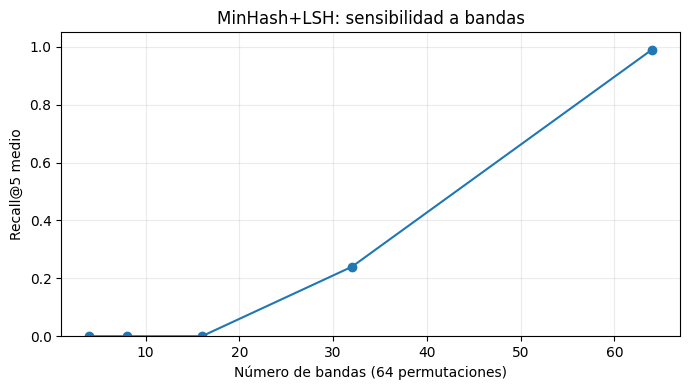

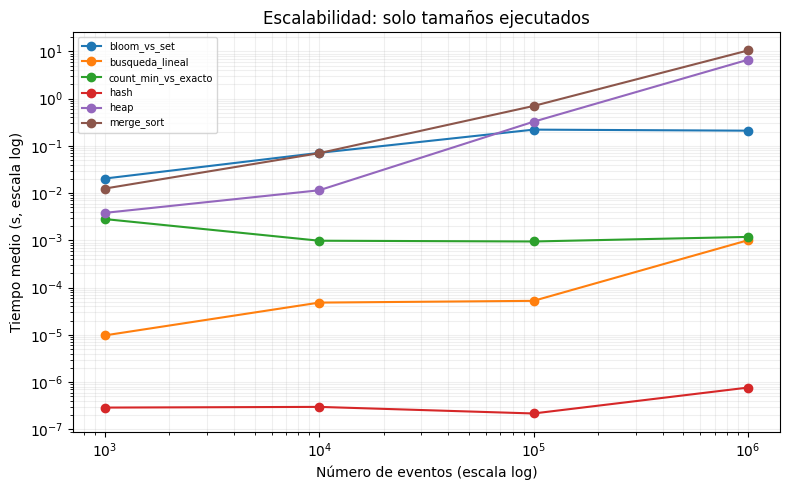

In [ ]:
# V5-D. Gráficos de evidencia. Solo se grafican mediciones existentes.
import matplotlib.pyplot as plt
if 'resumen_lsh_v5' in globals():
    fig,ax=plt.subplots(figsize=(7,4))
    ax.plot(resumen_lsh_v5['bandas'],resumen_lsh_v5['recall_medio'],marker='o')
    ax.set(xlabel='Número de bandas (64 permutaciones)',ylabel='Recall@5 medio',title='MinHash+LSH: sensibilidad a bandas')
    ax.set_ylim(0,1.05);ax.grid(True,alpha=.25)
    fig.tight_layout();fig.savefig(V5_DIR/'lsh_recall_bandas.png',dpi=160);plt.show()
if 'benchmarks' in globals():
    bb=benchmarks.copy()
    for col in ('n','tiempo_promedio_s'):
        bb[col]=pd.to_numeric(bb[col],errors='coerce')
    bb=bb[(bb.n>0)&(bb.tiempo_promedio_s>0)]
    if len(bb):
        fig,ax=plt.subplots(figsize=(8,5))
        for nombre,grupo in bb.groupby('estructura'):
            if grupo.n.nunique()>=2:
                grupo=grupo.sort_values('n');ax.loglog(grupo.n,grupo.tiempo_promedio_s,marker='o',label=nombre)
        ax.set(xlabel='Número de eventos (escala log)',ylabel='Tiempo medio (s, escala log)',title='Escalabilidad: solo tamaños ejecutados')
        ax.grid(True,which='both',alpha=.2);ax.legend(fontsize=7)
        fig.tight_layout();fig.savefig(V5_DIR/'escalabilidad_loglog.png',dpi=160);plt.show()
    else: print('Sin mediciones de tiempo positivas para gráfico log-log')

In [ ]:
# V5-E. Inventario de evidencias y advertencia de cobertura.
import platform
inventario={'modo':RUN_MODE,'semilla':SEED,'eventos_limpios':len(resultado['df']),
 'tamanos_benchmark_efectivos':sorted(set(map(int,benchmarks['n'].dropna()))) if 'benchmarks' in globals() else [],
 'plataforma':platform.platform(),
 'nota':'El modo quick NO demuestra 1M ni 10M. SQLite no es implementación propia de B+Tree persistente.'}
(V5_DIR/'inventario.json').write_text(json.dumps(inventario,indent=2,ensure_ascii=False),encoding='utf-8')
print(json.dumps(inventario,indent=2,ensure_ascii=False))
print('Archivos:',[p.name for p in V5_DIR.iterdir()])
print('Para descargar: !zip -r evidencias_eda_v5.zip evidencias_eda_v5')

{
  "modo": "full",
  "semilla": 42,
  "eventos_limpios": 9993786,
  "tamanos_benchmark_efectivos": [
    120,
    1000,
    10000,
    19180,
    20000,
    100000,
    1000000
  ],
  "plataforma": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "nota": "El modo quick NO demuestra 1M ni 10M. SQLite no es implementación propia de B+Tree persistente."
}
Archivos: ['comunidades_comparacion.csv', 'inventario.json', 'lsh_barrido_resumen.csv', 'lsh_recall_bandas.png', 'hnsw_vs_knn_multiconsulta.csv', 'escalabilidad_loglog.png', 'lsh_barrido_detalle.csv']
Para descargar: !zip -r evidencias_eda_v5.zip evidencias_eda_v5


## V6-A — B+Tree propio persistente en disco

Índice *bulk-load* con páginas de tamaño fijo (4096 bytes), nodos internos, hojas enlazadas, raíz y metadatos persistentes. Se construye a partir de pares `(precio, product_id)`, cierra el archivo, lo reabre y valida consultas por rango contra una búsqueda exacta. **Limitación declarada:** índice estático; una actualización requiere reconstrucción.

In [ ]:
import os, pickle, struct, tempfile, bisect, time, json, platform
from pathlib import Path
import numpy as np
import pandas as pd
V6_DIR=Path('evidencias_eda_v6'); V6_DIR.mkdir(exist_ok=True)

class BPlusTreeDisco:
    """B+Tree estático en páginas fijas, con hojas enlazadas y niveles internos."""
    PAGE=4096
    def __init__(self,ruta):
        self.ruta=str(ruta)
        self.f=open(self.ruta,'rb')
        meta=self._leer(0)
        assert meta['tipo']=='meta'
        self.root=meta['raiz'];self.n=meta['n'];self.altura=meta['altura']
    @classmethod
    def construir(cls,ruta,items,fanout=48,leaf_capacity=80):
        assert 3<=fanout<=100 and 2<=leaf_capacity<=100
        pares=sorted((float(precio),int(pid)) for precio,pid in items)
        def escribir(f,pg,obj):
            payload=pickle.dumps(obj,protocol=4)
            if len(payload)>cls.PAGE-4:raise ValueError('Página demasiado grande')
            f.seek(pg*cls.PAGE);f.write(struct.pack('<I',len(payload))+payload+b'\0'*(cls.PAGE-4-len(payload)))
        tmp=str(ruta)+'.tmp'
        with open(tmp,'wb') as f:
            escribir(f,0,{'tipo':'meta','raiz':0,'n':0,'altura':0})
            nivel=[];siguiente=1
            if not pares:
                escribir(f,1,{'tipo':'hoja','keys':[],'next':None});nivel=[(None,1)];siguiente=2
            else:
                chunks=[pares[i:i+leaf_capacity] for i in range(0,len(pares),leaf_capacity)]
                for j,chunk in enumerate(chunks):
                    pg=siguiente;siguiente+=1
                    escribir(f,pg,{'tipo':'hoja','keys':chunk,'next':pg+1 if j+1<len(chunks) else None})
                    nivel.append((chunk[0],pg))
            altura=1
            while len(nivel)>1:
                nuevo=[]
                for i in range(0,len(nivel),fanout):
                    grupo=nivel[i:i+fanout]
                    pg=siguiente;siguiente+=1
                    escribir(f,pg,{'tipo':'interno','separadores':[x[0] for x in grupo[1:]],'hijos':[x[1] for x in grupo]})
                    nuevo.append((grupo[0][0],pg))
                nivel=nuevo;altura+=1
            escribir(f,0,{'tipo':'meta','raiz':nivel[0][1],'n':len(pares),'altura':altura})
            f.flush();os.fsync(f.fileno())
        os.replace(tmp,ruta)
        return cls(ruta)
    def _leer(self,pg):
        self.f.seek(pg*self.PAGE)
        raw=self.f.read(4)
        if len(raw)!=4:raise IOError('Página inexistente')
        tam=struct.unpack('<I',raw)[0]
        if not 0<tam<=self.PAGE-4:raise IOError('Página inválida')
        return pickle.loads(self.f.read(tam))
    def rango(self,lo,hi):
        if lo>hi:return []
        pg=self.root
        while True:
            nodo=self._leer(pg)
            if nodo['tipo']=='hoja':break
            # bisect_right: claves iguales a un separador van al hijo derecho;
            # se indexa por (precio, id), buscando (precio, -infinito).
            idx=bisect.bisect_right(nodo['separadores'],(float(lo),float('-inf')))
            pg=nodo['hijos'][idx]
        salida=[]
        while True:
            for precio,pid in nodo['keys']:
                if precio>hi:return salida
                if precio>=lo:salida.append((precio,pid))
            if nodo['next'] is None:return salida
            nodo=self._leer(nodo['next'])
    def cerrar(self):self.f.close()

catalogo_v6=(resultado['df'][['product_id','price']].dropna().drop_duplicates('product_id'))
items_v6=list(catalogo_v6[['price','product_id']].itertuples(index=False,name=None))
# Guardamos el índice FUERA del TemporaryDirectory para exportar evidencia.
ruta_indice=V6_DIR/'indice_precios.bpt'
indice=BPlusTreeDisco.construir(ruta_indice,items_v6)
altura_v6=indice.altura;indice.cerrar()
indice=BPlusTreeDisco(ruta_indice)
assert indice.n==len(items_v6)
precios_v6=np.array([float(p) for p,_ in items_v6]);q_v6=np.quantile(precios_v6,[0,.1,.25,.5,.75,.9,1])
pruebas=[]
for lo,hi in [(float(q_v6[i]),float(q_v6[j])) for i,j in [(0,6),(1,3),(2,4),(4,5),(3,3)]] + [(160.86,304.25),(-1,0)]:
    esperado=sorted((float(p),int(pid)) for p,pid in items_v6 if lo<=float(p)<=hi)
    obtenido=indice.rango(lo,hi)
    assert obtenido==esperado, f'Diferencia rango {lo}-{hi}'
    pruebas.append({'min':lo,'max':hi,'coincide':True,'resultados':len(obtenido)})
indice.cerrar()
# Prueba adicional: nueva instancia, archivo persistido.
reabierto=BPlusTreeDisco(ruta_indice)
assert reabierto.rango(160.86,304.25)==sorted((float(p),int(pid)) for p,pid in items_v6 if 160.86<=float(p)<=304.25)
reabierto.cerrar()
pd.DataFrame(pruebas).to_csv(V6_DIR/'bplustree_validacion.csv',index=False)
print('B+Tree propio validado:',len(items_v6),'productos; altura:',altura_v6,'; bytes en disco:',ruta_indice.stat().st_size,'; rangos:',len(pruebas))
print('Nota: B+Tree de carga masiva estático, no admite inserciones incrementales.')

B+Tree propio validado: 121903 productos; altura: 3 ; bytes en disco: 6381568 ; rangos: 7
Nota: B+Tree de carga masiva estático, no admite inserciones incrementales.


## V6-B — Benchmarks reproducibles de rango

Comparación de B+Tree propio en disco contra escaneo lineal y `bisect` sobre un vector ordenado en memoria. Se miden **consultas**, sin incluir la construcción; la memoria del archivo se reporta separada de la RAM. Para escalas mayores se requiere ejecutar en modo `full` y contar con datos suficientes.

In [ ]:
import statistics, tracemalloc
from bisect import bisect_left,bisect_right
filas_bpt=[]
pares_ordenados=sorted((float(p),int(pid)) for p,pid in items_v6)
for n in (1000,10000,100000,1000000,10000000):
    if n>len(pares_ordenados):continue
    sub=pares_ordenados[:n]
    with tempfile.TemporaryDirectory() as td:
        idx=BPlusTreeDisco.construir(os.path.join(td,'index.bpt'),sub)
        valores=[p for p,_ in sub]
        lo,hi=np.quantile(valores,[.35,.65]).tolist()
        esperado=[x for x in sub if lo<=x[0]<=hi]
        def scan():return [x for x in sub if lo<=x[0]<=hi]
        def binary():return sub[bisect_left(sub,(lo,-1)):bisect_right(sub,(hi,float('inf')))]
        def disk():return idx.rango(lo,hi)
        assert scan()==binary()==disk()==esperado
        reps=100 if n<=10000 else (30 if n<=100000 else 3)
        for metodo,func in [('escaneo',scan),('bisect_ram',binary),('bplustree_disco',disk)]:
            tiempos=[]
            for _ in range(reps):
                t0=time.perf_counter();func();tiempos.append(time.perf_counter()-t0)
            filas_bpt.append({'n_productos':n,'metodo':metodo,'repeticiones':reps,'media_s':float(np.mean(tiempos)),
               'desv_s':float(np.std(tiempos,ddof=1)) if reps>1 else 0.,'resultados':len(esperado),
               'tamano_archivo_bytes':os.path.getsize(idx.ruta) if metodo=='bplustree_disco' else 0,
               'semilla':SEED,'plataforma':platform.platform()})
        idx.cerrar()
tabla_bpt_v6=pd.DataFrame(filas_bpt)
tabla_bpt_v6.to_csv(V6_DIR/'bplustree_benchmark.csv',index=False)
print(tabla_bpt_v6[['n_productos','metodo','repeticiones','media_s','desv_s']].to_string(index=False))
print('ATENCIÓN: n_productos no es n_eventos. La escala máxima depende del catálogo disponible.')

 n_productos          metodo  repeticiones  media_s   desv_s
        1000         escaneo           100 0.000133 0.000011
        1000      bisect_ram           100 0.000008 0.000003
        1000 bplustree_disco           100 0.000477 0.000033
       10000         escaneo           100 0.002535 0.000588
       10000      bisect_ram           100 0.000034 0.000012
       10000 bplustree_disco           100 0.001722 0.000282
      100000         escaneo            30 0.026879 0.001246
      100000      bisect_ram            30 0.000327 0.000064
      100000 bplustree_disco            30 0.010609 0.000772
ATENCIÓN: n_productos no es n_eventos. La escala máxima depende del catálogo disponible.


## V6-C — Escalabilidad de eventos y cobertura real

Medimos operaciones reproducibles sobre prefijos de eventos **sin fabricar muestras de 1M o 10M**. Las repeticiones son adaptativas; en el informe se declara si no alcanzan las 100 solicitadas. La gráfica log-log muestra únicamente tamaños efectivamente ejecutados.

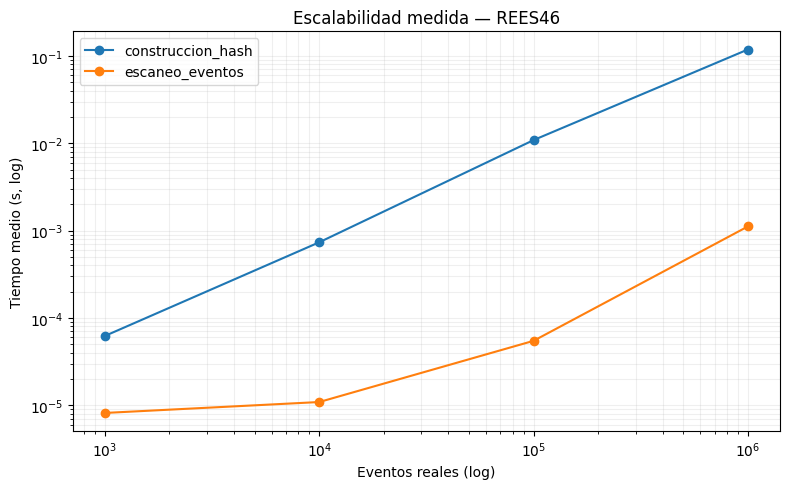

Tamaños medidos: [1000, 10000, 100000, 1000000]
Advertencia: no se extrapolan ni inventan tamaños ausentes.


In [ ]:
import matplotlib.pyplot as plt
filas_esc_v6=[]
ids_eventos_v6=resultado['df']['product_id'].astype('int64').to_numpy()
for n in (1000,10000,100000,1000000,10000000):
    if n>len(ids_eventos_v6):continue
    muestra=ids_eventos_v6[:n]
    # Medimos construcción y consulta de hash, separadamente de la búsqueda lineal.
    pruebas={'escaneo_eventos':lambda m=muestra: bool(np.any(m==-1)),
             'construccion_hash':lambda m=muestra: set(m.tolist())}
    for nombre,fn in pruebas.items():
        reps=100 if n<=100000 else 3
        tiempos=[]
        for _ in range(reps):
            t0=time.perf_counter();fn();tiempos.append(time.perf_counter()-t0)
        filas_esc_v6.append({'n_eventos':n,'operacion':nombre,'repeticiones':reps,
            'media_s':float(np.mean(tiempos)),'desv_s':float(np.std(tiempos,ddof=1)) if reps>1 else 0.,
            'seed':SEED,'plataforma':platform.platform()})
tabla_esc_v6=pd.DataFrame(filas_esc_v6)
tabla_esc_v6.to_csv(V6_DIR/'escalabilidad_eventos.csv',index=False)
fig,ax=plt.subplots(figsize=(8,5))
for nombre,g in tabla_esc_v6.groupby('operacion'):
    ax.plot(g.n_eventos,g.media_s,marker='o',label=nombre)
ax.set(xscale='log',yscale='log',xlabel='Eventos reales (log)',ylabel='Tiempo medio (s, log)',title='Escalabilidad medida — REES46')
ax.grid(True,which='both',alpha=.2);ax.legend();fig.tight_layout()
fig.savefig(V6_DIR/'escalabilidad_eventos_loglog.png',dpi=160);plt.show()
print('Tamaños medidos:',sorted(tabla_esc_v6.n_eventos.unique().tolist()))
print('Advertencia: no se extrapolan ni inventan tamaños ausentes.')

In [ ]:
# V6-D. Inventario verificable y paquete descargable
import json, zipfile
inventario_v6={'version':'v6','dataset':DATASET_FILE,'modo':RUN_MODE,'seed':SEED,
 'eventos_crudos':len(crudo),'eventos_limpios':len(resultado['df']),
 'escalas_eventos_medidas':sorted(map(int,tabla_esc_v6.n_eventos.unique())),
 'escalas_catalogo_medidas':sorted(map(int,tabla_bpt_v6.n_productos.unique())),
 'bplustree_tipo':'implementación propia, estática, carga masiva, páginas persistentes y hojas enlazadas',
 'bplustree_actualizaciones_incrementales':False,
 'limite':'No se acredita 1M o 10M si no aparecen en las tablas. El B+Tree propio es estático.'}
(V6_DIR/'inventario_v6.json').write_text(json.dumps(inventario_v6,indent=2,ensure_ascii=False),encoding='utf-8')
with zipfile.ZipFile('evidencias_eda_v6.zip','w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in V6_DIR.iterdir():z.write(p,arcname='evidencias_eda_v6/'+p.name)
print(json.dumps(inventario_v6,indent=2,ensure_ascii=False))
print('ZIP generado: evidencias_eda_v6.zip')

{
  "version": "v6",
  "dataset": "2019-Oct.csv",
  "modo": "full",
  "seed": 42,
  "eventos_crudos": 10000000,
  "eventos_limpios": 9993786,
  "escalas_eventos_medidas": [
    1000,
    10000,
    100000,
    1000000
  ],
  "escalas_catalogo_medidas": [
    1000,
    10000,
    100000
  ],
  "bplustree_tipo": "implementación propia, estática, carga masiva, páginas persistentes y hojas enlazadas",
  "bplustree_actualizaciones_incrementales": false,
  "limite": "No se acredita 1M o 10M si no aparecen en las tablas. El B+Tree propio es estático."
}
ZIP generado: evidencias_eda_v6.zip


## V7 — Benchmark controlado para la presentación final

- Compara **escaneo Python secuencial** y **consulta a hash preconstruido** con la misma clave ausente; distingue costo de construcción.
- Usa calentamiento, lotes de consultas repetidas y temporización por lote para reducir ruido.
- Registra desviación, pico de memoria de la **construcción** y checksum de las consultas.
- En `quick`, utiliza solo los eventos cargados; para medir 1M/10M, cambiar a `full` y **verificar que el CSV realmente contiene esas filas y que Colab dispone de memoria suficiente**. El benchmark v7 usa arrays de IDs y no replica el dataset.
- La ejecución completa de las secciones anteriores puede ser costosa en `full`; no se garantiza viabilidad en Colab gratuito.

In [ ]:
# V7-A. Mediciones comparables y verificables
from pathlib import Path
import gc, json, statistics, tracemalloc, time, platform
import numpy as np
import pandas as pd
V7_DIR=Path('evidencias_eda_v7');V7_DIR.mkdir(exist_ok=True)
ids_v7=resultado['df']['product_id'].astype('int64').to_numpy()

def cronometrar_lotes(fn, repeticiones=15, minimo_segundos=0.015):
    # Un lote contiene tantas llamadas como se requiera para superar el ruido del reloj.
    for _ in range(3): fn()
    llamadas=1
    while True:
        inicio=time.perf_counter()
        checksum=0
        for _ in range(llamadas): checksum+=int(bool(fn()))
        duracion=time.perf_counter()-inicio
        if duracion>=minimo_segundos or llamadas>=100000:break
        llamadas*=2
    muestras=[]
    for _ in range(repeticiones):
        t0=time.perf_counter();total=0
        for _ in range(llamadas): total+=int(bool(fn()))
        muestras.append((time.perf_counter()-t0)/llamadas)
        assert total==checksum, 'Resultado no determinista'
    return float(np.mean(muestras)),float(np.std(muestras,ddof=1)),llamadas,checksum

filas_v7=[]
for n_eventos in [1000,10000,100000,1000000,10000000]:
    if n_eventos>len(ids_v7):continue
    muestra=ids_v7[:n_eventos]
    clave_ausente=-1
    # Preconstrucción fuera del tiempo de consulta; construcción se mide aparte.
    hash_ids=set(map(int,muestra))
    def scan_py(m=muestra,k=clave_ausente):
        for valor in m:
            if int(valor)==k:return True
        return False
    def consulta_hash(h=hash_ids,k=clave_ausente):return k in h
    def construir_hash(m=muestra):return set(map(int,m))
    # Evitamos multiplicar el trabajo del escaneo largo por cientos de repeticiones.
    reps=15 if n_eventos<=100000 else 5
    for nombre,func in [('escaneo_python',scan_py),('consulta_hash_preconstruido',consulta_hash),('construccion_hash',construir_hash)]:
        if nombre=='escaneo_python' and n_eventos>=1000000:
            # El cronómetro de lotes igualmente funciona con una llamada por lote.
            reps=5
        media,desv,llamadas,checksum=cronometrar_lotes(func,reps,0.005 if n_eventos>=100000 else 0.015)
        filas_v7.append({'n_eventos':n_eventos,'operacion':nombre,'media_s':media,
           'desv_s':desv,'repeticiones':reps,'llamadas_por_lote':llamadas,
           'checksum':checksum,'semilla':SEED,'plataforma':platform.platform()})
    del hash_ids
    gc.collect()
tabla_v7=pd.DataFrame(filas_v7)
tabla_v7.to_csv(V7_DIR/'benchmark_controlado.csv',index=False)
print(tabla_v7.to_string(index=False))
print('Escalas medidas:',sorted(map(int,tabla_v7.n_eventos.unique())))

 n_eventos                   operacion      media_s       desv_s  repeticiones  llamadas_por_lote  checksum  semilla                           plataforma
      1000              escaneo_python 1.094447e-04 7.592876e-06            15                256         0       42 Linux-6.6.122+-x86_64-with-glibc2.39
      1000 consulta_hash_preconstruido 1.483743e-07 3.066792e-08            15             131072         0       42 Linux-6.6.122+-x86_64-with-glibc2.39
      1000           construccion_hash 1.167678e-04 6.782824e-06            15                256       256       42 Linux-6.6.122+-x86_64-with-glibc2.39
     10000              escaneo_python 1.071887e-03 3.960973e-05            15                 16         0       42 Linux-6.6.122+-x86_64-with-glibc2.39
     10000 consulta_hash_preconstruido 1.538220e-07 2.975935e-08            15             131072         0       42 Linux-6.6.122+-x86_64-with-glibc2.39
     10000           construccion_hash 1.191428e-03 5.212377e-05            

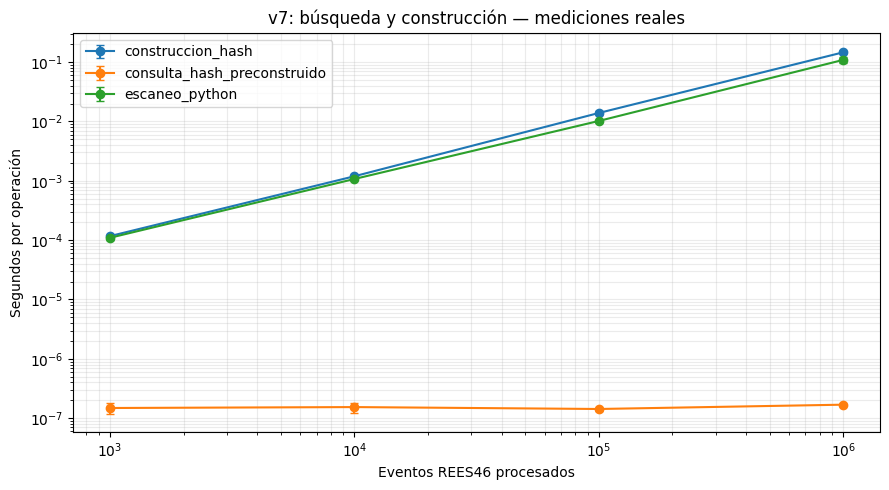

 n_eventos  pico_memoria_python_mb  elementos_unicos                                           nota
      1000                0.048729               534 tracemalloc: asignaciones Python; no RSS total
     10000                0.252130              4150 tracemalloc: asignaciones Python; no RSS total
    100000                3.100349             20625 tracemalloc: asignaciones Python; no RSS total
   1000000                3.933343             63336 tracemalloc: asignaciones Python; no RSS total


In [ ]:
# V7-B. Gráfica y pico de memoria para construcción de hash
import matplotlib.pyplot as plt
filas_mem=[]
for n_eventos in [1000,10000,100000,1000000,10000000]:
    if n_eventos>len(ids_v7):continue
    muestra=ids_v7[:n_eventos]
    gc.collect();tracemalloc.start()
    construido=set(map(int,muestra))
    actual,pico=tracemalloc.get_traced_memory();tracemalloc.stop()
    filas_mem.append({'n_eventos':n_eventos,'pico_memoria_python_mb':pico/1024**2,
       'elementos_unicos':len(construido),'nota':'tracemalloc: asignaciones Python; no RSS total'})
    del construido
mem_v7=pd.DataFrame(filas_mem)
mem_v7.to_csv(V7_DIR/'memoria_hash.csv',index=False)
fig,ax=plt.subplots(figsize=(9,5))
for nombre,g in tabla_v7.groupby('operacion'):
    ax.errorbar(g.n_eventos,g.media_s,yerr=g.desv_s,marker='o',capsize=3,label=nombre)
ax.set(xscale='log',yscale='log',xlabel='Eventos REES46 procesados',ylabel='Segundos por operación',
       title='v7: búsqueda y construcción — mediciones reales')
ax.grid(True,which='both',alpha=.25);ax.legend();fig.tight_layout()
fig.savefig(V7_DIR/'benchmark_controlado_loglog.png',dpi=160)
plt.show()
print(mem_v7.to_string(index=False))

## V7 — Checklist y demostración en vivo (3–4 minutos)

1. **Problema y datos (30 s):** explicar eventos `view`, `cart`, `purchase`, limpieza y corte temporal sin fuga de información.
2. **Arquitectura (45 s):** recorrer FIFO, merge sort/búsqueda binaria, heap, hash/LRU, B+Tree persistente, KD-Tree/HNSW, Bloom/CMS, LSH, grafo y Top-K/dashboard. Señalar qué componentes son prototipos y cuáles se usan en la ruta principal.
3. **Demo (60–90 s):** usar dashboard de las celdas anteriores; procesar `view` y `purchase`, mostrar recomendación y decisión de fraude. No prometer fraude real: es una regla demostrativa, no un clasificador validado.
4. **Evidencia (45 s):** mostrar tablas de recomendación val/test, barrido LSH, HNSW exacto, comunidades, validación B+Tree y benchmark controlado v7.
5. **Límites (20 s):** B+Tree bulk-load sin inserciones; catálogo y eventos son escalas distintas; `quick` no acredita 1M/10M; la curva puede incluir efectos de caché y hardware.

**Preguntas esperables:** ¿por qué la búsqueda binaria en RAM gana al B+Tree? ¿por qué 64 bandas mejora recall pero aumenta candidatos? ¿por qué el grafo supera al híbrido? ¿qué diferencia hay entre un filtro Bloom y un hash exacto? ¿qué impide afirmar que un sistema de fraude está validado?

In [ ]:
# V7-C. Auditoría de cobertura y paquete final. No se fabrican métricas.
import zipfile, json, shutil
cobertura_v7={
 'version':'v7','dataset':DATASET_FILE,'run_mode':RUN_MODE,'seed':SEED,
 'eventos_crudos_leidos':int(len(crudo)),'eventos_limpios':int(len(resultado['df'])),
 'escalas_v7_medidas':sorted(map(int,tabla_v7.n_eventos.unique())),
 'catalogo_bplustree_productos':int(len(items_v6)),
 'bplustree_persistente':bool(ruta_indice.exists()),
 'bplustree_bulk_load_sin_actualizaciones':True,
 'nota':'Los resultados corresponden a esta ejecución. No se extrapolan a escalas ausentes.'}
(V7_DIR/'inventario_v7.json').write_text(json.dumps(cobertura_v7,ensure_ascii=False,indent=2),encoding='utf8')
# Adjuntamos evidencia histórica de v4/v5/v6 cuando está presente en esta ejecución.
for folder in ('evidencias_eda_v4','evidencias_eda_v5','evidencias_eda_v6'):
    origen=Path(folder)
    if origen.is_dir():
        destino=V7_DIR/folder
        shutil.copytree(origen,destino,dirs_exist_ok=True)
with zipfile.ZipFile('evidencias_eda_v7.zip','w',zipfile.ZIP_DEFLATED) as z:
    for p in V7_DIR.rglob('*'):
        if p.is_file():z.write(p,arcname=str(p))
print(json.dumps(cobertura_v7,ensure_ascii=False,indent=2))
print('Generado: evidencias_eda_v7.zip')

{
  "version": "v7",
  "dataset": "2019-Oct.csv",
  "run_mode": "full",
  "seed": 42,
  "eventos_crudos_leidos": 10000000,
  "eventos_limpios": 9993786,
  "escalas_v7_medidas": [
    1000,
    10000,
    100000,
    1000000
  ],
  "catalogo_bplustree_productos": 121903,
  "bplustree_persistente": true,
  "bplustree_bulk_load_sin_actualizaciones": true,
  "nota": "Los resultados corresponden a esta ejecución. No se extrapolan a escalas ausentes."
}
Generado: evidencias_eda_v7.zip
